In [1]:
# ==============================
# Start of execution
# ==============================
import time
start = time.time()

# 📦 Amazon Reviews 2023 (Video Games) — Sequential Recommender Systems

**Notebook goal:** understand the business problem of an e-commerce store, explore how customers' interactions evolve over time (EDA), and build recommender systems that predict **the next product a customer will interact with**, moving from **unsupervised** baselines to **self-supervised** sequential deep learning models.

**Dataset:** [Amazon Reviews 2023 (McAuley Lab)](https://amazon-reviews-2023.github.io/), category **Video Games**, official **5-core** benchmark (users and products with at least 5 interactions) + product metadata.

> **Demonstrates:** ✅ Self-supervised learning · ✅ Unsupervised learning · 📦 E-commerce

---

## 1. Business Understanding

### 1.1 Context
**Industry: E-commerce / online retail.** Amazon sells millions of products; in the Video Games category alone, tens of thousands of games, consoles and accessories compete for the customer's attention. Customers do not browse the catalog: they rely on recommendations on the home page, product pages, the cart and e-mails.

What a customer needs **next** depends on what they **just** did: someone who bought a new console will soon need games, controllers and storage; someone who finished a game is likely to look for its sequel.

### 1.2 Business Question
> **Given the sequence of products a customer has interacted with, which product will they interact with next?**

### 1.3 Why It Matters — Business Value

| In-store use case | Benefit | Related KPI |
|---|---|---|
| **"Inspired by your recent activity"** (home page) | Recommendations that follow the customer's current interests | Click-through rate, conversion |
| **"Customers who bought this also bought"** (product page) | Cross-selling of complementary products (console → games → accessories) | Attach rate, average order value |
| **Post-purchase recommendations** (order confirmation, e-mail) | Brings the customer back with the logical next purchase | Repeat purchase rate, e-mail CTR |
| **New releases and sequels** | Matches customers with the next entry of the franchises they follow | Pre-orders, launch sales |
| **Catalog discovery** | Exposes relevant products beyond best-sellers | Catalog coverage, long-tail sales |

At its core, this is a **conversion and customer lifetime value** problem: anticipating the next need turns a single purchase into a recurring relationship.

### 1.4 What Makes This Problem Different (vs. Instacart and MovieLens)

| | Instacart (retail) | MovieLens (streaming) | **Amazon (e-commerce)** |
|---|---|---|---|
| **Feedback** | Implicit (purchases) | Explicit (ratings) | **Implicit (reviews as a proxy for purchases), with ratings** |
| **Repetition** | Very high (reorders) | None | **Low**: customers rarely buy the same game twice |
| **Order of interactions** | Weekly baskets | Not informative (bulk rating sessions) | **Informative**: what comes next depends on what came before |
| **History per user** | Long (median 10 orders) | Long (median 96 ratings) | **Short**: a few interactions per customer |
| **Time span** | Weeks | \~3 years | **Decades** (1996–2023): products, consoles and trends change |

Additional challenges:
1. **Extreme sparsity:** short histories and a large catalog.
2. **Reviews are a proxy:** customers review only a fraction of what they buy, so the data shows *reviewed* purchases, not all purchases.
3. **Catalog dynamics:** new consoles and games constantly replace old ones; a good model must capture **recency and trends**.
4. **Cold start:** many products have only a handful of interactions.

### 1.5 Framing as a Machine Learning Problem
- **Next-item prediction:** given a customer's chronological sequence of products $(i_1, i_2, \dots, i_t)$, rank the whole catalog so that $i_{t+1}$ appears at the top.
- **Self-supervised learning:** the training signal comes **from the sequences themselves**: each prefix of a sequence is an input and the following item is its label. No manual labels or external targets are needed.
- **Evaluation:** **Hit Rate@K** (= Recall@K for a single target item) and **NDCG@K**, ranking **all products in the catalog** (no sampled negatives), plus **catalog coverage**.

**Learning paradigms covered**
| Paradigm | Approach |
|---|---|
| **Unsupervised** | Popularity and item co-occurrence (*"customers who bought X also bought Y"*), item-to-item **transition** patterns |
| **Self-supervised** | Sequential neural models: **GRU4Rec** (recurrent network) and **SASRec** (self-attention / Transformer) trained to predict the next item |

### 1.6 Validation Scheme
We use the standard **leave-one-out** protocol of the official benchmark: for each customer, the **last** interaction is the **test** target, the **second-to-last** is the **validation** target, and all earlier interactions form the **training** sequence. Every interaction keeps its timestamp, so models always **use the past to predict the next interaction**, with no data leakage.

## 2. Setup

Import libraries, check the GPU (needed later for the sequential neural models), define global parameters and plotting style, and download the data from the official **Amazon Reviews 2023** repository on Hugging Face:

| File | Content |
|---|---|
| `benchmark/5core/last_out_w_his/Video_Games.train.csv` | All training interactions (one row per interaction, with the previous history) |
| `benchmark/5core/last_out_w_his/Video_Games.valid.csv` | Second-to-last interaction of each user (validation target) |
| `benchmark/5core/last_out_w_his/Video_Games.test.csv` | Last interaction of each user (test target) |
| `raw/meta_categories/meta_Video_Games.jsonl` | Product metadata: title, category, price, store (brand), rating, … |

In [2]:
# ==============================
# Libraries
# ==============================
import warnings, json, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import torch

warnings.filterwarnings("ignore")

# ==============================
# Global parameters
# ==============================
DATA_DIR = Path("data")
CATEGORY = "Video_Games"
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"pandas {pd.__version__} | numpy {np.__version__} | torch {torch.__version__}")
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else
                             " — enable a GPU in Colab for the neural models (Runtime → Change runtime type)"))

# ==============================
# Display options and plotting style
# ==============================
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe6", "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})

def pct_axis(ax, axis="y"):
    """Format an axis as percentage (0-1 scale)."""
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(mtick.PercentFormatter(1.0))

pandas 2.2.3 | numpy 2.4.6 | torch 2.14.1+cu130
Device: cuda (NVIDIA L4)


In [3]:
# ==============================
# Download benchmark files and product metadata (Hugging Face)
# ==============================
from huggingface_hub import hf_hub_download

REPO = "McAuley-Lab/Amazon-Reviews-2023"
DATA_DIR.mkdir(exist_ok=True)

files = {split: f"benchmark/5core/last_out_w_his/{CATEGORY}.{split}.csv" for split in ["train", "valid", "test"]}
files["meta"] = f"raw/meta_categories/meta_{CATEGORY}.jsonl"

paths = {}
for name, fname in files.items():
    paths[name] = Path(hf_hub_download(repo_id=REPO, filename=fname, repo_type="dataset", local_dir=DATA_DIR))
    print(f"{name:<6} {paths[name].stat().st_size / 1e6:>8.1f} MB  ←  {fname}")

train      88.1 MB  ←  benchmark/5core/last_out_w_his/Video_Games.train.csv


valid      12.4 MB  ←  benchmark/5core/last_out_w_his/Video_Games.valid.csv
test       13.4 MB  ←  benchmark/5core/last_out_w_his/Video_Games.test.csv
meta      437.4 MB  ←  raw/meta_categories/meta_Video_Games.jsonl


## 3. Data Loading

**Interactions (official 5-core, leave-one-out benchmark)**

| File | Granularity | Columns |
|---|---|---|
| `train.csv` | 1 row per training interaction | `user_id`, `parent_asin`, `rating`, `timestamp` (ms), `history` (previous items, space-separated) |
| `valid.csv` | 1 row per user: **second-to-last** interaction | same |
| `test.csv` | 1 row per user: **last** interaction | same |

- **5-core:** every user and every product has at least 5 interactions.
- **Item ID:** `parent_asin` groups the variants of a product (e.g., editions, colors) under one ID.
- **Interaction = review:** each row is a review written by the customer, used as a proxy for a purchase. It includes the star rating, but the sequential task only uses **which** product came **when**.

**Product metadata** (`meta_Video_Games.jsonl`): title, store (brand / publisher), price, average rating, number of ratings, and a category path (e.g., *Video Games › PlayStation 4 › Accessories › Controllers*), from which we extract the **platform** and the **product type**.

**Transformations:**
- Merge the three splits into one interaction table and build each user's **chronological sequence** (train items + validation item + test item).
- Check that the benchmark's `history` column is consistent with the rebuilt sequences.
- Keep metadata only for products that appear in the interactions.

In [4]:
# ==============================
# Load interactions (train / valid / test)
# ==============================
dtypes = {"user_id": "string", "parent_asin": "string", "rating": "float32", "timestamp": "int64", "history": "string"}
splits = {s: pd.read_csv(paths[s], dtype=dtypes) for s in ["train", "valid", "test"]}

inter = pd.concat([df.assign(split=s) for s, df in splits.items()], ignore_index=True)
inter["split"] = pd.Categorical(inter["split"], categories=["train", "valid", "test"], ordered=True)
inter["datetime"] = pd.to_datetime(inter["timestamp"], unit="ms")

# Chronological order within each user: train interactions by time, then valid, then test
inter = inter.sort_values(["user_id", "split", "timestamp"], kind="stable").reset_index(drop=True)
inter["pos"] = inter.groupby("user_id").cumcount() + 1                 # position in the user's sequence
inter["seq_len"] = inter.groupby("user_id")["parent_asin"].transform("size")

# ==============================
# Integer IDs (0 is reserved for padding in the neural models)
# ==============================
user_ids = inter["user_id"].unique()
item_ids = inter["parent_asin"].unique()
user2idx = pd.Series(np.arange(len(user_ids)), index=user_ids)
item2idx = pd.Series(np.arange(1, len(item_ids) + 1), index=item_ids)
inter["u"] = inter["user_id"].map(user2idx).astype("int32")
inter["i"] = inter["parent_asin"].map(item2idx).astype("int32")
N_USERS, N_ITEMS = len(user_ids), len(item_ids)

# One chronological sequence of item indices per user
sequences = inter.groupby("u")["i"].apply(np.array)

print(f"Interactions: {len(inter):,} | users: {N_USERS:,} | items: {N_ITEMS:,}")
display(inter["split"].value_counts().sort_index().to_frame("interactions"))

# ==============================
# Consistency checks
# ==============================
print("Each user has exactly one valid and one test interaction:",
      (inter[inter["split"] != "train"].groupby(["user_id", "split"], observed=True).size() == 1).all()
      and inter.loc[inter["split"] == "test", "user_id"].nunique() == N_USERS)

last2 = inter[inter["pos"] >= inter["seq_len"] - 1]
last_two = last2.groupby("user_id")["split"].apply(lambda s: "|".join(s.astype(str)))
print("Valid and test are each user's last two interactions:", (last_two == "valid|test").all())

same_user = inter["user_id"].eq(inter["user_id"].shift())
backwards = same_user & (inter["timestamp"] < inter["timestamp"].shift())
order_ok = 1 - inter.loc[backwards, "user_id"].nunique() / N_USERS
print(f"Users whose sequence is in non-decreasing time order: {order_ok:.2%}")

# The benchmark 'history' of the test row must equal all previous items of the user
hist_test = inter.loc[inter["split"] == "test"].set_index("user_id")["history"].fillna("").str.split()
prev_items = inter[inter["split"] != "test"].groupby("user_id")["parent_asin"].apply(list)
sample_u = hist_test.sample(2_000, random_state=SEED).index
match = np.mean([hist_test[u][-len(prev_items[u]):] == prev_items[u][-len(hist_test[u]):] for u in sample_u])
print(f"Benchmark history matches the rebuilt sequence (sample of 2,000 users): {match:.1%}")

Interactions: 814,586 | users: 94,762 | items: 25,612


,interactions
split,
train,625062
valid,94762
test,94762


Each user has exactly one valid and one test interaction: True
Valid and test are each user's last two interactions: True
Users whose sequence is in non-decreasing time order: 100.00%
Benchmark history matches the rebuilt sequence (sample of 2,000 users): 100.0%


In [5]:
# ==============================
# Product metadata (only products in the benchmark)
# ==============================
keep = set(item_ids)
fields = ["parent_asin", "title", "main_category", "store", "price", "average_rating", "rating_number", "categories"]
rows = []
with open(paths["meta"], "r") as f:
    for line in f:
        rec = json.loads(line)
        if rec.get("parent_asin") in keep:
            rows.append({k: rec.get(k) for k in fields})

meta = pd.DataFrame(rows).drop_duplicates("parent_asin").set_index("parent_asin")
meta["price"] = pd.to_numeric(meta["price"], errors="coerce")

# Category path, e.g. ["Video Games", "PlayStation 4", "Accessories", "Controllers"]
cats = meta["categories"].apply(lambda c: [x for x in (c or []) if x != "Video Games"])
meta["platform"] = cats.str[0]                  # first level after "Video Games" (usually the platform)
meta["product_type"] = cats.str[1]              # second level (Games, Accessories, Consoles, …)
raw_categories = meta["categories"].copy()      # raw category paths, kept for robust parsing in section 4
meta = meta.drop(columns="categories")

meta = meta.reindex(item_ids)                   # same order as item indices (index 1 … N_ITEMS)
print(f"Products with metadata: {meta['title'].notna().sum():,} of {N_ITEMS:,} ({meta['title'].notna().mean():.1%})")
display(meta.head(5))

Products with metadata: 25,612 of 25,612 (100.0%)


,title,main_category,store,price,average_rating,rating_number,platform,product_type
parent_asin,,,,,,,,
B082R1RGZF,Turtle Beach Stealth 300 Amplified Surround So...,Video Games,Turtle Beach,NaN,4.400,2124,Xbox One,Accessories
B07SNN8GV5,Call of Duty: Modern Warfare Battle Pass Editi...,Video Games,ACTIVISION,NaN,4.600,447,Xbox One,Games
B01GY35T4S,Xbox One S 1TB Console - NBA 2K20 Bundle - [DI...,All Electronics,Xbox,275.000,4.700,1216,Xbox One,Consoles
B07QX99XJJ,Corsair HS35 - Stereo Gaming Headset - Memory ...,Computers,Corsair,41.990,4.300,9036,PC,Accessories
B0BW17W9GM,Corsair HS55 Surround Gaming Headset (Leathere...,Computers,Corsair,42.770,4.400,3558,PC,Accessories


In [6]:
# ==============================
# First look
# ==============================
display(inter[["user_id", "parent_asin", "rating", "datetime", "split", "pos", "seq_len"]].head(8))

overview = pd.Series({
    "Interactions": len(inter),
    "Users": N_USERS,
    "Items": N_ITEMS,
    "Avg. interactions per user": len(inter) / N_USERS,
    "Median interactions per user": inter.groupby("u").size().median(),
    "Avg. interactions per item": len(inter) / N_ITEMS,
    "Density of user × item matrix": len(inter) / (N_USERS * N_ITEMS),
}, name="value")
display(overview.to_frame().style.format("{:,.4f}").format("{:,.0f}", subset=pd.IndexSlice[["Interactions", "Users", "Items"], :])
        .format("{:.4%}", subset=pd.IndexSlice[["Density of user × item matrix"], :]))

print(f"Time span: {inter['datetime'].min():%Y-%m-%d} → {inter['datetime'].max():%Y-%m-%d}")
print("Platforms (top 10):", meta["platform"].value_counts().head(10).to_dict())
print("Product types (top 10):", meta["product_type"].value_counts().head(10).to_dict())

,user_id,parent_asin,rating,datetime,split,pos,seq_len
0,AE222HFZDH6BPTYFOUWGGU63YSIQ,B082R1RGZF,5.000,2019-07-16 23:36:57.391,train,1,5
1,AE222HFZDH6BPTYFOUWGGU63YSIQ,B07SNN8GV5,5.000,2019-12-15 14:32:20.876,train,2,5
2,AE222HFZDH6BPTYFOUWGGU63YSIQ,B01GY35T4S,5.000,2020-01-04 18:08:57.203,train,3,5
3,AE222HFZDH6BPTYFOUWGGU63YSIQ,B07QX99XJJ,5.000,2020-03-01 18:45:21.887,valid,4,5
4,AE222HFZDH6BPTYFOUWGGU63YSIQ,B0BW17W9GM,5.000,2020-06-28 17:43:47.132,test,5,5
5,AE2252DKW4XJIZP5QPFMQVJBVRTA,B0050SX4CI,4.000,2012-11-08 07:23:09.000,train,1,11
6,AE2252DKW4XJIZP5QPFMQVJBVRTA,B002ORTCAQ,5.000,2013-01-08 21:13:54.000,train,2,11
7,AE2252DKW4XJIZP5QPFMQVJBVRTA,B0090ECASW,1.000,2013-01-15 20:38:24.000,train,3,11


,value
Interactions,"814,586"
Users,"94,762"
Items,"25,612"
Avg. interactions per user,8.5961
Median interactions per user,6.0000
Avg. interactions per item,31.8049
Density of user × item matrix,0.0336%


Time span: 1999-10-22 → 2023-09-02
Platforms (top 10): {'Legacy Systems': 11708, 'PC': 6355, 'Nintendo Switch': 2268, 'PlayStation 4': 1824, 'Xbox One': 1446, 'PlayStation 5': 292, 'Mac': 155, 'PlayStation Digital Content': 143, 'Xbox Series X & S': 135, 'Game Genre of the Month': 84}
Product types (top 10): {'Accessories': 6407, 'Nintendo Systems': 5270, 'Games': 5045, 'PlayStation Systems': 3759, 'Xbox Systems': 2077, 'Virtual Reality': 567, 'Sega Systems': 443, 'Consoles': 164, 'Microconsoles': 75, 'Downloadable Content': 64}


## 4. Data Quality

Checks before the EDA:

1. **Missing values** in interactions and product metadata.
2. **Duplicates** — the same user reviewing the same product more than once (repeated items in a sequence).
3. **Value ranges** — ratings 1–5, timestamps, **ties** (several reviews with the same timestamp).
4. **Dataset guarantees** — 5-core: every user and product has at least 5 interactions.
5. **Cold-start products in validation / test** — products that never appear in the training data cannot be learned by any ID-based model.
6. **Category path parsing** — the path is not uniform across products (e.g., older consoles are nested under *Legacy Systems*), so platform and product type must be extracted with a more robust rule.

In [7]:
# ==============================
# 4.1 Missing values
# ==============================
print("Missing values in interactions:")
display(inter[["user_id", "parent_asin", "rating", "timestamp"]].isna().sum().to_frame("n_missing").T)

meta_missing = pd.DataFrame({"n_missing": meta.isna().sum(), "share_missing": meta.isna().mean()})
print("Missing values in product metadata:")
display(meta_missing.style.format({"n_missing": "{:,}", "share_missing": "{:.1%}"}))

# ==============================
# 4.2 Duplicates and repeated items
# ==============================
dup_rows = inter.duplicated(["user_id", "parent_asin", "timestamp"]).sum()
rep_pairs = inter.duplicated(["user_id", "parent_asin"]).sum()
users_with_rep = inter.loc[inter.duplicated(["user_id", "parent_asin"], keep=False), "user_id"].nunique()
print(f"\nExact duplicate rows (user, item, timestamp): {dup_rows:,}")
print(f"Repeated (user, item) pairs: {rep_pairs:,} ({rep_pairs / len(inter):.2%} of interactions) "
      f"— {users_with_rep:,} users ({users_with_rep / N_USERS:.1%})")

test_rows = inter[inter["split"] == "test"]
prev_sets = inter[inter["split"] != "test"].groupby("u")["i"].apply(set)
test_repeat = np.mean([i in prev_sets.get(u, set()) for u, i in zip(test_rows["u"], test_rows["i"])])
print(f"Test items already in the user's previous history (repeat purchases): {test_repeat:.2%}")

# ==============================
# 4.3 Value ranges and timestamp ties
# ==============================
print(f"\nRating values: {sorted(inter['rating'].unique())}")
print(f"Time span: {inter['datetime'].min():%Y-%m-%d} → {inter['datetime'].max():%Y-%m-%d}")

tie = inter["user_id"].eq(inter["user_id"].shift()) & inter["timestamp"].eq(inter["timestamp"].shift())
print(f"Interactions with the same timestamp as the user's previous one: {tie.sum():,} ({tie.mean():.2%})")

# ==============================
# 4.4 5-core guarantee
# ==============================
per_user = inter.groupby("u").size()
per_item = inter.groupby("i").size()
print(f"\nInteractions per user: min = {per_user.min()} | per item: min = {per_item.min()}")

# ==============================
# 4.5 Cold-start items in validation / test (never seen in training)
# ==============================
train_items = set(inter.loc[inter["split"] == "train", "i"])
for s in ["valid", "test"]:
    split_rows = inter[inter["split"] == s]
    unseen = ~split_rows["i"].isin(train_items)
    print(f"{s.capitalize():<5} targets on items never seen in training: {unseen.sum():,} ({unseen.mean():.2%})")
items_only_eval = N_ITEMS - len(train_items)
print(f"Items that appear only in validation / test: {items_only_eval:,} ({items_only_eval / N_ITEMS:.1%} of the catalog)")

Missing values in interactions:


,user_id,parent_asin,rating,timestamp
n_missing,0,0,0,0


Missing values in product metadata:


,n_missing,share_missing
title,0,0.0%
main_category,514,2.0%
store,120,0.5%
price,"8,481",33.1%
average_rating,0,0.0%
rating_number,0,0.0%
platform,869,3.4%
product_type,"1,534",6.0%



Exact duplicate rows (user, item, timestamp): 0
Repeated (user, item) pairs: 0 (0.00% of interactions) — 0 users (0.0%)
Test items already in the user's previous history (repeat purchases): 0.00%

Rating values: [np.float32(1.0), np.float32(2.0), np.float32(3.0), np.float32(4.0), np.float32(5.0)]
Time span: 1999-10-22 → 2023-09-02
Interactions with the same timestamp as the user's previous one: 61 (0.01%)

Interactions per user: min = 5 | per item: min = 5
Valid targets on items never seen in training: 163 (0.17%)
Test  targets on items never seen in training: 345 (0.36%)
Items that appear only in validation / test: 85 (0.3% of the catalog)


In [8]:
# ==============================
# 4.6 Robust parsing of the category path
# ==============================
raw_paths = raw_categories.reindex(item_ids).apply(lambda c: [x for x in (c if isinstance(c, list) else []) if x != "Video Games"])

print("Most common category paths:")
display(raw_paths.apply(lambda c: " › ".join(c[:3])).value_counts().head(15).to_frame("products"))

TYPE_WORDS = {"Games", "Accessories", "Consoles", "Digital Games", "Virtual Reality",
              "Online Game Services", "Downloadable Content", "Gaming Keyboards", "Controllers"}

def parse_path(c):
    """Product type = first level that is a known type; platform = the level right before it."""
    for k, level in enumerate(c):
        if level in TYPE_WORDS:
            return (c[k - 1] if k > 0 else None), level
    return (c[-1] if c else None), None

parsed = raw_paths.apply(parse_path)
meta["platform"] = parsed.str[0]
meta["product_type"] = parsed.str[1]

# Platform family (Nintendo, PlayStation, Xbox, PC, …)
def family(p):
    if p is None or pd.isna(p): return "Unknown"
    p = str(p)
    for key, fam in [("Nintendo", "Nintendo"), ("Wii", "Nintendo"), ("Game Boy", "Nintendo"), ("GameCube", "Nintendo"),
                     ("Switch", "Nintendo"), ("PlayStation", "PlayStation"), ("PSP", "PlayStation"), ("Xbox", "Xbox"),
                     ("PC", "PC"), ("Mac", "PC"), ("Linux", "PC"), ("Sega", "Sega")]:
        if key in p: return fam
    return "Other"

meta["platform_family"] = meta["platform"].apply(family)

print("Product type:")
display(meta["product_type"].value_counts(dropna=False).head(10).to_frame("products"))
print("Platform (top 15):")
display(meta["platform"].value_counts(dropna=False).head(15).to_frame("products"))
print("Platform family:")
display(meta["platform_family"].value_counts().to_frame("products"))

Most common category paths:


,products
categories,
PC › Games,2833
Legacy Systems › Xbox Systems › Xbox 360,1375
Legacy Systems › Nintendo Systems › Wii,1241
Legacy Systems › PlayStation Systems › PlayStation 3,1189
Legacy Systems › PlayStation Systems › PlayStation 2,1109
Legacy Systems › Nintendo Systems › Nintendo DS,969
Legacy Systems › Nintendo Systems › Nintendo 3DS & 2DS,932
,869
PlayStation 4 › Games,856


Product type:


,products
product_type,
Games,11450
Accessories,10134
None,2692
Virtual Reality,621
Consoles,590
Downloadable Content,88
Online Game Services,37


Platform (top 15):


,products
platform,
PC,6355
Nintendo Switch,2265
PlayStation 4,1802
Xbox One,1442
Xbox 360,1374
Wii,1237
PlayStation 3,1129
PlayStation 2,1109
Nintendo DS,969


Platform family:


,products
platform_family,
Nintendo,7466
PC,6514
PlayStation,5951
Xbox,3658
Unknown,960
Other,620
Sega,443


### 4.7 Data Quality — Key Findings

**Interactions** ✅
- **No missing values** in user, product, rating or timestamp.
- **No duplicates and no repeated items:** no user reviewed the same product twice (0 repeated user–product pairs). The benchmark keeps one interaction per user–product pair, so **the next item is always new to the user** (0.00% of test targets were already in the user's history).
- Ratings are whole stars (1–5); time span **1999-10-22 → 2023-09-02** (\~24 years).
- **Timestamps are reliable:** only **61 interactions (0.01%)** share their timestamp with the user's previous one, and every sequence is in chronological order. Unlike MovieLens, the **order of interactions is meaningful**.
- **5-core guarantee confirmed:** every user and every product has **at least 5 interactions**.

**Leave-one-out split** ✅
- Every user has exactly one validation and one test interaction, and they are the user's **last two** interactions; the benchmark `history` column matches the rebuilt sequences (100%).
- **Cold-start targets are negligible:** only **163 validation (0.17%)** and **345 test (0.36%)** targets are products never seen in training (85 products, 0.3% of the catalog). ID-based models can reach at most \~99.6% of test targets.

**Product metadata**
- **100%** of products have metadata (title, average rating, number of ratings).
- **Price is missing for 33.1%** of products (mostly older or discontinued items) → price can be used for description, but not as a reliable feature.
- `main_category` is missing for 2.0% and `store` (brand / publisher) for 0.5%.

**Category path (fixed)**
- The category path is **not uniform**: modern platforms follow *Platform › Type* (e.g., *PC › Games*, *PlayStation 4 › Games*), while older consoles are nested under *Legacy Systems › Brand Systems › Console* (e.g., *Legacy Systems › Xbox Systems › Xbox 360*). A naive "first level = platform" rule labeled 11.7k products as "Legacy Systems".
- With a robust rule (product type = first known type level; platform = level before it, or the deepest level when no type is present):

| Product type | Products | | Platform family | Products |
|---|---|---|---|---|
| Games | 11,450 (44.7%) | | Nintendo | 7,466 (29.2%) |
| Accessories | 10,134 (39.6%) | | PC | 6,514 (25.4%) |
| Unknown | 2,692 (10.5%) | | PlayStation | 5,951 (23.2%) |
| Virtual Reality | 621 | | Xbox | 3,658 (14.3%) |
| Consoles | 590 | | Sega / Other / Unknown | 2,023 (7.9%) |
| DLC & online services | 125 | | | |

- **Top platforms:** PC (6,355), Nintendo Switch (2,265), PlayStation 4 (1,802), Xbox One (1,442), Xbox 360 (1,374), Wii (1,237), PlayStation 3 (1,129), PlayStation 2 (1,109).
- **Unknown** type (10.5%) mainly corresponds to legacy-console products whose path stops at the console level, plus \~3.4% of products with an empty category path.

**Implications for the recommender**
- **Pure discovery:** since users never repeat a product, models must always recommend **unseen items**, and previously interacted items are excluded from recommendations.
- **Order matters:** reliable timestamps make **sequential models** appropriate.
- **A clean benchmark:** almost no cold-start targets, so results reflect the models' ability to learn from sequences, not missing data.
- **Platform and product type** are meaningful product attributes for the EDA (e.g., console → games → accessories transitions) and for describing recommendations.

## 5. Exploratory Data Analysis (EDA)

The EDA is guided by questions that matter for a **sequential** recommender:

| Block | Question | Why it matters for recommendations |
|---|---|---|
| **5.1 Users** | How long are sequences? How much time passes between interactions? | How much context each model has; maximum sequence length for neural models |
| **5.2 Products** | How concentrated is popularity? Which platforms and product types dominate? | Popularity bias, catalog coverage |
| **5.3 Time** | How does activity change over 24 years? How fast do products age? | Recency and trends; which items are still relevant |
| **5.4 Sequences** | Does the next item depend on the previous one (same platform, type, franchise)? | Whether **order** carries signal → justification for sequential models |
| **5.5 Co-occurrence & transitions** | Which products are bought together or one after another? | Basis for item-to-item and transition models |

*Note: to avoid leakage, statistics that inform modeling choices are computed on **training** interactions when relevant; descriptive statistics use all interactions.*

---

### 5.1 Users: How Long Are Their Sequences?

**Questions:**
- How many interactions does each user have? How many users have very short sequences?
- How concentrated is activity across users?
- How much time passes between consecutive interactions, and between the last training interaction and the test target (**prediction horizon**)?
- How long is a user's lifetime on the platform?

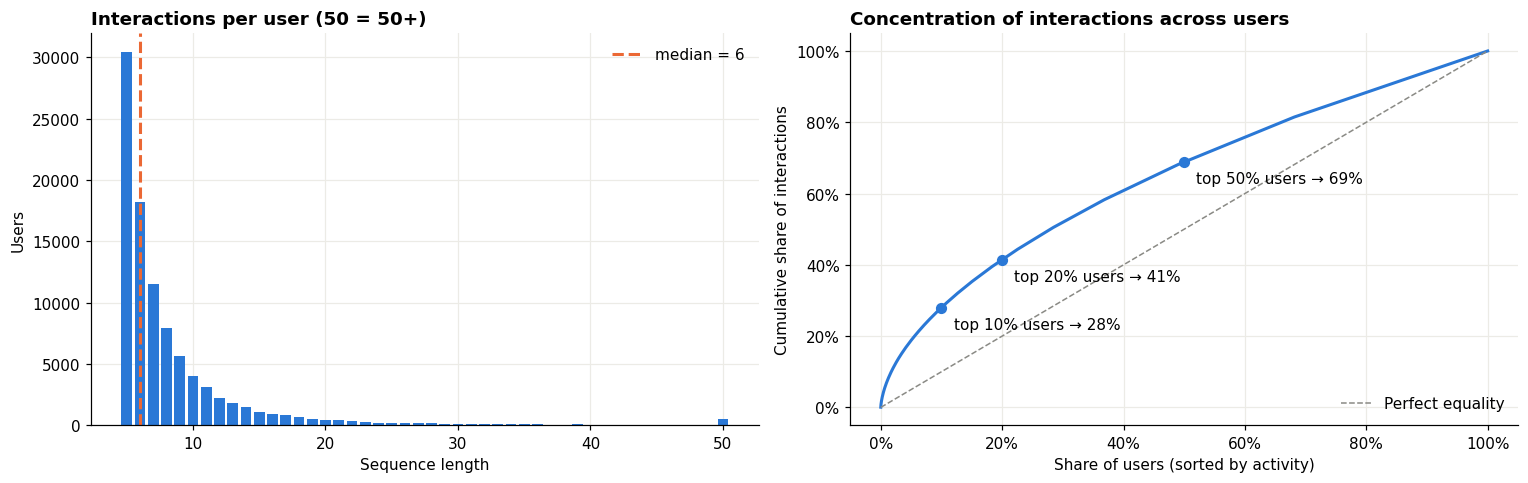

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
interactions_per_user,"94,762.000",8.596,7.898,5.000,5.000,6.000,9.000,14.000,19.000,38.000,473.000


,users,share_users,share_interactions
5,"30,451",32.1%,18.7%
6–7,"29,707",31.3%,23.3%
8–10,"17,534",18.5%,18.9%
11–20,"13,180",13.9%,22.4%
21–50,"3,417",3.6%,12.1%
50+,473,0.5%,4.6%


Training sequence length (excluding valid + test): median = 4, users with only 3 training items: 32.1%
Users whose full sequence fits in 20 items: 95.9%
Users whose full sequence fits in 50 items: 99.5%
Users whose full sequence fits in 100 items: 99.9%


In [9]:
# ==============================
# 5.1.1 Sequence length per user
# ==============================
seq_len = inter.groupby("u").size()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

counts = seq_len.clip(upper=50).value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=BLUE, width=0.8)
axes[0].axvline(seq_len.median(), color=ORANGE, ls="--", lw=2, label=f"median = {seq_len.median():.0f}")
axes[0].set(title="Interactions per user (50 = 50+)", xlabel="Sequence length", ylabel="Users")
axes[0].legend(frameon=False)

sorted_n = np.sort(seq_len.values)[::-1]
cum = np.cumsum(sorted_n) / sorted_n.sum()
share_u = np.arange(1, len(sorted_n) + 1) / len(sorted_n)
axes[1].plot(share_u, cum, color=BLUE, lw=2)
axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Perfect equality")
for p in (0.10, 0.20, 0.50):
    v = cum[int(p * len(cum)) - 1]
    axes[1].scatter([p], [v], color=BLUE, s=40, zorder=3)
    axes[1].annotate(f"top {p:.0%} users → {v:.0%}", (p, v), xytext=(8, -14), textcoords="offset points")
axes[1].set(title="Concentration of interactions across users",
            xlabel="Share of users (sorted by activity)", ylabel="Cumulative share of interactions")
axes[1].legend(frameon=False, loc="lower right")
pct_axis(axes[1]); pct_axis(axes[1], "x")

plt.tight_layout()
plt.show()

display(seq_len.describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame("interactions_per_user").T)

len_bins = [4, 5, 7, 10, 20, 50, np.inf]
len_labels = ["5", "6–7", "8–10", "11–20", "21–50", "50+"]
len_tbl = pd.cut(seq_len, bins=len_bins, labels=len_labels).value_counts().sort_index().to_frame("users")
len_tbl["share_users"] = len_tbl["users"] / N_USERS
len_tbl["share_interactions"] = seq_len.groupby(pd.cut(seq_len, bins=len_bins, labels=len_labels),
                                                observed=True).sum() / len(inter)
display(len_tbl.style.format({"users": "{:,}", "share_users": "{:.1%}", "share_interactions": "{:.1%}"}))

print(f"Training sequence length (excluding valid + test): median = {(seq_len - 2).median():.0f}, "
      f"users with only 3 training items: {((seq_len - 2) == 3).mean():.1%}")
for L in (20, 50, 100):
    print(f"Users whose full sequence fits in {L} items: {(seq_len <= L).mean():.1%}")

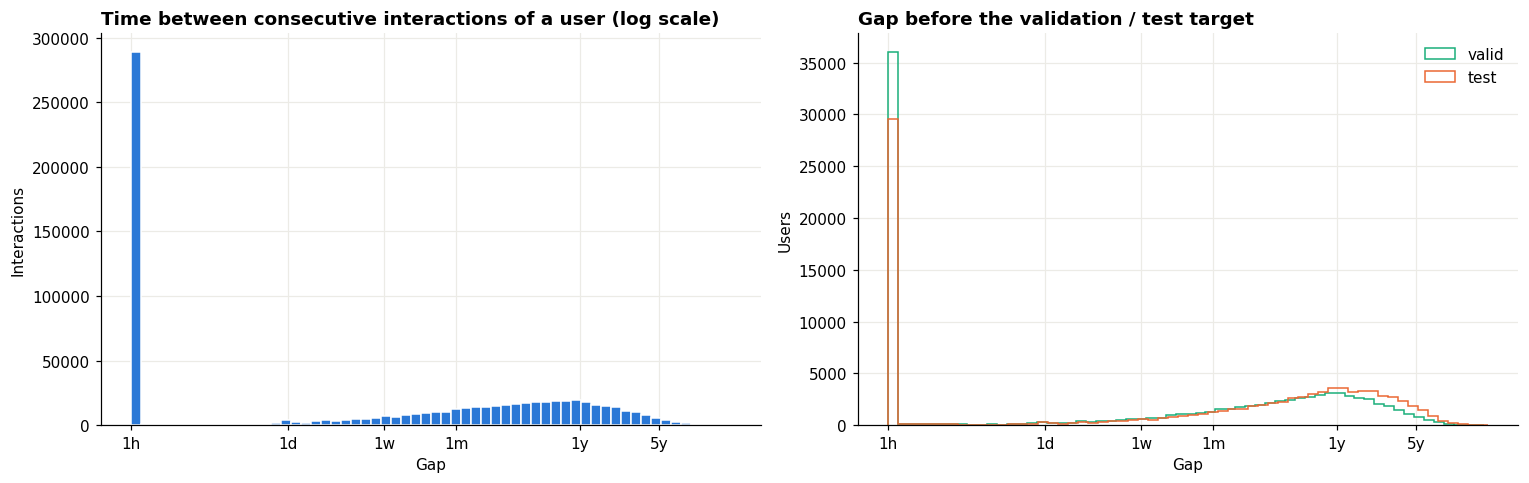

,count,mean,std,min,25%,50%,75%,90%,max
all gaps,"719,824.0",186.7,419.3,0.0,0.0,11.2,172.2,571.0,"7,754.8"
gap before valid target,"94,762.0",231.0,454.4,0.0,0.0,26.8,264.0,710.9,"7,095.9"
gap before test target,"94,762.0",345.2,589.3,0.0,0.0,79.1,433.0,"1,071.8","7,754.8"


Consecutive interactions same day (< 1 day): 42.4%
Consecutive interactions within a week: 47.7%
Consecutive interactions within a month: 56.6%
Consecutive interactions more than a year: 15.2%

User lifetime (first → last interaction): median = 3.0 years, p25 = 0.9, p75 = 5.9
Users whose whole sequence spans less than 1 month: 11.5%


In [10]:
# ==============================
# 5.1.2 Time between consecutive interactions
# ==============================
gap_days = (inter.groupby("u")["timestamp"].diff() / 86_400_000).dropna()      # ms → days
inter["gap_days"] = inter.groupby("u")["timestamp"].diff() / 86_400_000

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(np.log10(gap_days.clip(lower=1 / 24)), bins=60, color=BLUE, edgecolor="white")
ticks = [1 / 24, 1, 7, 30, 365, 365 * 5]
axes[0].set_xticks(np.log10(ticks))
axes[0].set_xticklabels(["1h", "1d", "1w", "1m", "1y", "5y"])
axes[0].set(title="Time between consecutive interactions of a user (log scale)",
            xlabel="Gap", ylabel="Interactions")

# Prediction horizon: from the last training interaction to the validation / test target
horizon = {s: inter.loc[inter["split"] == s, "gap_days"] for s in ["valid", "test"]}
for s, c in [("valid", GREEN), ("test", ORANGE)]:
    axes[1].hist(np.log10(horizon[s].clip(lower=1 / 24)), bins=60, histtype="step", lw=2, color=c, label=s)
axes[1].set_xticks(np.log10(ticks))
axes[1].set_xticklabels(["1h", "1d", "1w", "1m", "1y", "5y"])
axes[1].set(title="Gap before the validation / test target", xlabel="Gap", ylabel="Users")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

gap_tbl = pd.DataFrame({
    "all gaps": gap_days.describe(percentiles=[.25, .5, .75, .9]),
    "gap before valid target": horizon["valid"].describe(percentiles=[.25, .5, .75, .9]),
    "gap before test target": horizon["test"].describe(percentiles=[.25, .5, .75, .9]),
}).T
display(gap_tbl.style.format("{:,.1f}"))

for lim, lab in [(1, "same day (< 1 day)"), (7, "within a week"), (30, "within a month"), (365, "more than a year")]:
    share = (gap_days < lim).mean() if lim != 365 else (gap_days > 365).mean()
    print(f"Consecutive interactions {lab}: {share:.1%}")

# ==============================
# 5.1.3 User lifetime (first → last interaction)
# ==============================
life_years = inter.groupby("u")["timestamp"].agg(lambda t: (t.max() - t.min()) / (86_400_000 * 365.25))
print(f"\nUser lifetime (first → last interaction): median = {life_years.median():.1f} years, "
      f"p25 = {life_years.quantile(.25):.1f}, p75 = {life_years.quantile(.75):.1f}")
print(f"Users whose whole sequence spans less than 1 month: {(life_years < 1 / 12).mean():.1%}")

### 5.1 Users — Key Findings

**1. Sequences are short**
| Interactions per user | 5 | 6–7 | 8–10 | 11–20 | 21–50 | 50+ |
|---|---|---|---|---|---|---|
| Users | 32.1% | 31.3% | 18.5% | 13.9% | 3.6% | 0.5% |
| Share of interactions | 18.7% | 23.3% | 18.9% | 22.4% | 12.1% | 4.6% |

- **Median of 6 interactions per user** (mean 8.6, max 473); **1 in 3 users has exactly 5**, the 5-core minimum.
- After holding out the validation and test targets, the **median training sequence has only 4 items**, and **32.1% of users train with just 3 items**.
- Activity is only moderately concentrated: the **top 20% of users** generate **41%** of interactions (vs. 57% in MovieLens).
- **95.9%** of users fit in 20 items, **99.5%** in 50 items and **99.9%** in 100 items.

**2. Time between interactions is bimodal: sessions vs. separate purchases**
- **42.4%** of consecutive interactions happen on the **same day**, most of them **within one hour**: customers review **several products at once**, likely items from the **same order** (e.g., a console, a game and a controller).
- The rest are spread over **months to years**: median gap 11.2 days, p75 = 172 days, p90 = 571 days; **15.2%** of gaps exceed one year.
- → Two different kinds of "next item": **same-session items** (complements bought together) and **later purchases** (when interests, platforms and catalog may have changed).

**3. The prediction horizon is long for most users**
| Gap before the target | Median | p75 | p90 |
|---|---|---|---|
| Validation target | 26.8 days | 264 days | 711 days |
| **Test target** | **79.1 days** | **433 days** | **1,072 days** |

- About **30k users (\~31%)** write their test review **within the same hour** as the previous one (same session); for the others, the test interaction comes **months or years later**.
- The test horizon is longer than the validation horizon: the last interaction tends to happen after a longer pause, making **test harder than validation**.

**4. Users stay for years, with sporadic activity**
- Median user lifetime (first → last interaction): **3.0 years** (p25 = 0.9, p75 = 5.9); **11.5%** of users have their whole sequence within one month.
- With a median of 6 interactions over 3 years, customers write a review only **occasionally**: each sequence is a sparse sample of their purchase history.

**Implications for the recommender**
- **Little context per user:** with 3–4 training items for most users, models must learn from **very short sequences** → collaborative signals from other users and **item-to-item transitions** are essential.
- **Maximum sequence length:** **50 items** covers 99.5% of users and is the standard choice for SASRec; longer sequences add cost for almost no users.
- **Recency matters:** the most recent items are likely the best predictors, especially within a session (complements of the last purchase).
- **Time gaps are informative:** same-session transitions (bundles) and long-gap transitions (next purchase) behave differently; time-aware variants of the models could exploit this, and results can be **analyzed by gap** (same session vs. later).
- **Long horizons cap accuracy:** when the next interaction comes a year later, interests may have changed, so offline accuracy will be modest for many users.

### 5.2 Products: What Do Customers Interact With?

**Questions:**
- How concentrated is popularity? Do a few best-sellers receive most interactions (**popularity bias**)?
- How many products have very few interactions (hard to learn)?
- Which products are the most popular?
- Which **platforms** and **product types** concentrate interactions, compared with their share of the catalog?
- How are ratings distributed? (They are not the target, but they describe customer satisfaction.)

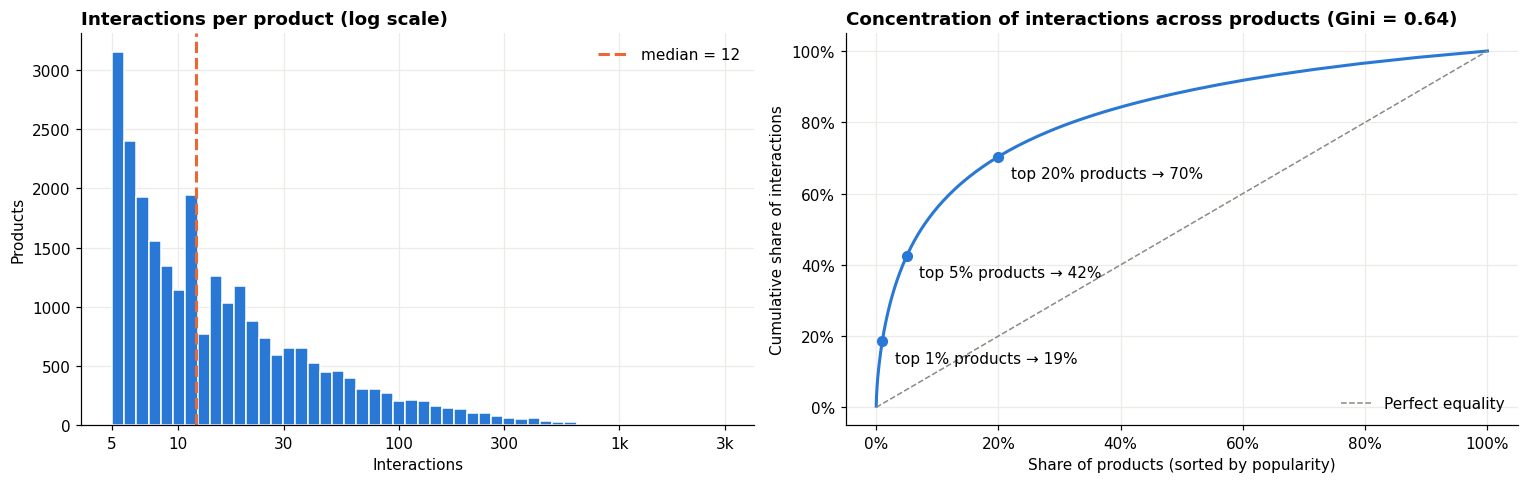

,count,mean,std,min,25%,50%,75%,90%,99%,max
interactions_per_product,"25,612.000",31.805,78.046,5.000,7.000,12.000,26.000,64.000,340.890,"2,955.000"


Products with < 10 interactions: 10,386 (40.6%)
Products with < 20 interactions: 17,363 (67.8%)
Products with < 50 interactions: 22,199 (86.7%)

Top 15 products by interactions:


,title,platform,product_type,store,interactions,share,average_rating
i,,,,,,,
257,amFilm Tempered Glass Screen Protector for Nintendo Switch 2017 (2-Pac,Nintendo Switch,Accessories,amFilm,"2,955",0.36%,4.8
167,Grand Theft Auto V: Premium Edition - Xbox One [Digital Code],Xbox One,Games,Rockstar Games,"2,306",0.28%,4.6
59,Skyrim VR - PlayStation 4,PlayStation 4,Games,Bethesda,"2,296",0.28%,4.6
95,PlayStation 4 500GB Console [Old Model][Discontinued],None,None,PlayStation,"1,904",0.23%,4.6
57,DualShock 4 Wireless Controller for PlayStation 4 - Jet Black,PlayStation 4,Accessories,PlayStation,"1,857",0.23%,4.7
342,Xbox Live Gold: 1 Month Membership [Digital Code],Subscription Cards,None,Xbox,"1,841",0.23%,4.7
780,PlayStation Plus: 12 Month Membership [Digital Code],None,Online Game Services,PlayStation,"1,781",0.22%,4.8
684,Fallout 4 - Xbox One,Xbox One,Games,Bethesda,"1,687",0.21%,4.6
165,Battlefield 4 - Playstation 3,PlayStation 3,Games,Electronic Arts,"1,545",0.19%,4.4


In [11]:
# ==============================
# 5.2.1 Interactions per product and concentration
# ==============================
n_per_item = inter.groupby("i").size().sort_values(ascending=False)
cum_i = np.cumsum(n_per_item.values) / n_per_item.sum()
share_i = np.arange(1, len(n_per_item) + 1) / len(n_per_item)
asc = np.sort(n_per_item.values)
gini_items = 1 - 2 * (np.cumsum(asc) / asc.sum()).mean() + 1 / len(asc)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(np.log10(n_per_item), bins=50, color=BLUE, edgecolor="white")
axes[0].axvline(np.log10(n_per_item.median()), color=ORANGE, ls="--", lw=2, label=f"median = {n_per_item.median():.0f}")
axes[0].set_xticks(np.log10([5, 10, 30, 100, 300, 1000, 3000]))
axes[0].set_xticklabels(["5", "10", "30", "100", "300", "1k", "3k"])
axes[0].set(title="Interactions per product (log scale)", xlabel="Interactions", ylabel="Products")
axes[0].legend(frameon=False)

axes[1].plot(share_i, cum_i, color=BLUE, lw=2)
axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Perfect equality")
for p in (0.01, 0.05, 0.20):
    v = cum_i[int(p * len(cum_i)) - 1]
    axes[1].scatter([p], [v], color=BLUE, s=40, zorder=3)
    axes[1].annotate(f"top {p:.0%} products → {v:.0%}", (p, v), xytext=(8, -14), textcoords="offset points")
axes[1].set(title=f"Concentration of interactions across products (Gini = {gini_items:.2f})",
            xlabel="Share of products (sorted by popularity)", ylabel="Cumulative share of interactions")
axes[1].legend(frameon=False, loc="lower right")
pct_axis(axes[1]); pct_axis(axes[1], "x")
plt.tight_layout()
plt.show()

display(n_per_item.describe(percentiles=[.25, .5, .75, .9, .99]).to_frame("interactions_per_product").T)
for t in (10, 20, 50):
    k = (n_per_item < t).sum()
    print(f"Products with < {t} interactions: {k:,} ({k / N_ITEMS:.1%})")

# ==============================
# 5.2.2 Most popular products
# ==============================
top = n_per_item.head(15).rename("interactions").to_frame()
info = meta.reset_index(drop=True)
info.index = np.arange(1, N_ITEMS + 1)                        # align with item indices
top = top.join(info[["title", "platform", "product_type", "store", "average_rating"]])
top["title"] = top["title"].str.slice(0, 70)
top["share"] = top["interactions"] / len(inter)
print("\nTop 15 products by interactions:")
display(top[["title", "platform", "product_type", "store", "interactions", "share", "average_rating"]]
        .style.format({"interactions": "{:,}", "share": "{:.2%}", "average_rating": "{:.1f}"}))

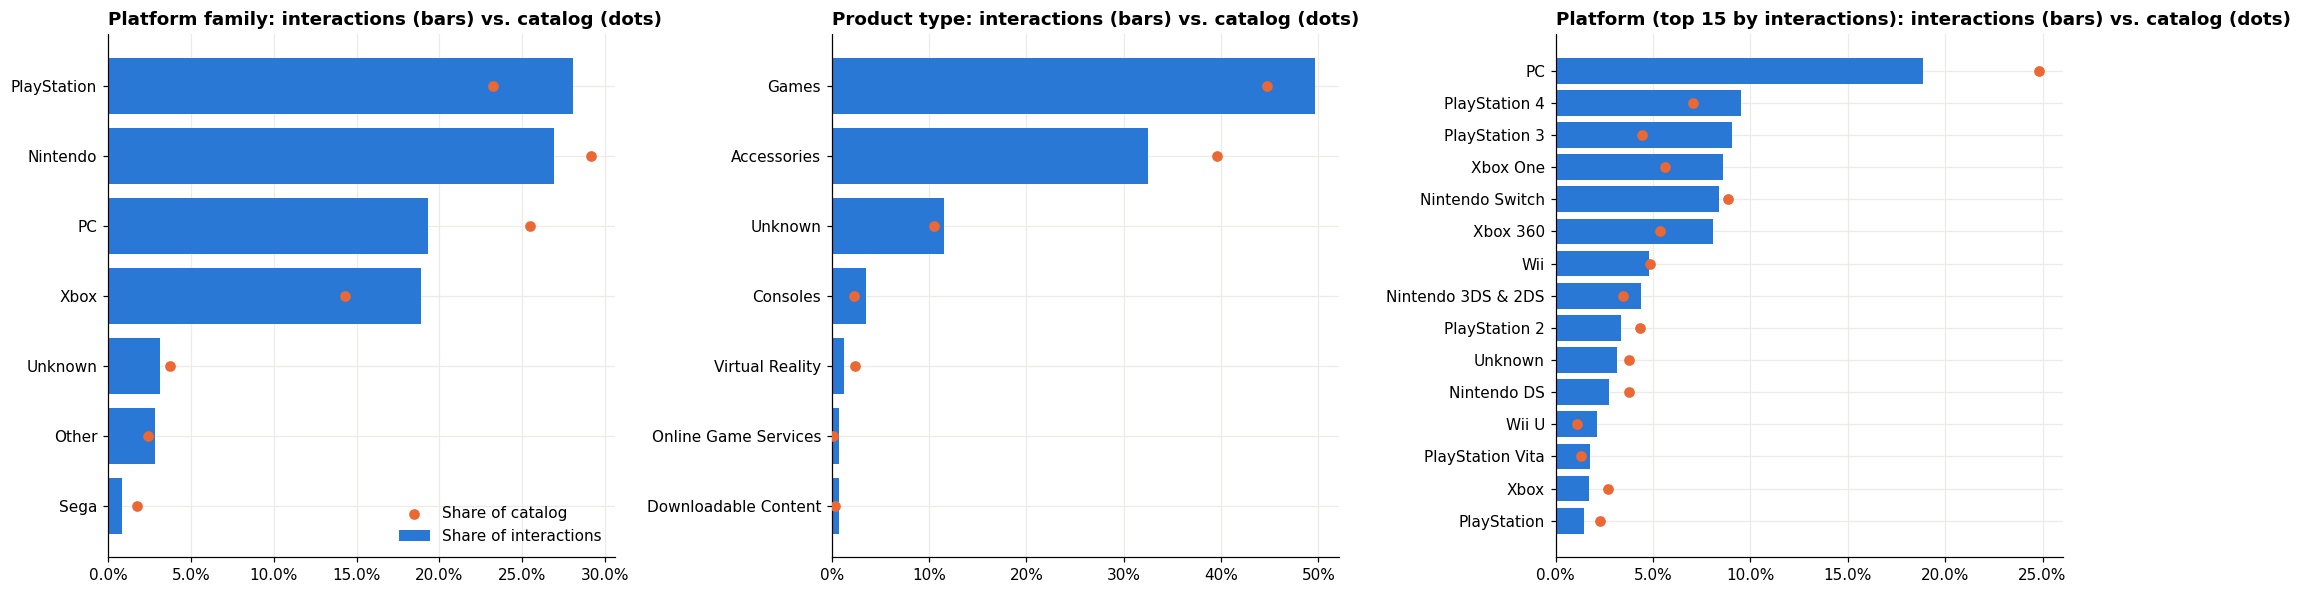

Product type:


,share_of_catalog,share_of_interactions,interactions_per_product
product_type,,,
Games,44.7%,49.7%,35
Accessories,39.6%,32.5%,26
Unknown,10.5%,11.5%,35
Consoles,2.3%,3.6%,49
Virtual Reality,2.4%,1.3%,16
Online Game Services,0.1%,0.8%,169
Downloadable Content,0.3%,0.8%,70


Platform (top 15):


,share_of_catalog,share_of_interactions,interactions_per_product
platform,,,
PC,24.8%,18.9%,24
PlayStation 4,7.0%,9.5%,43
PlayStation 3,4.4%,9.1%,65
Xbox One,5.6%,8.6%,48
Nintendo Switch,8.8%,8.4%,30
Xbox 360,5.4%,8.1%,48
Wii,4.8%,4.8%,32
Nintendo 3DS & 2DS,3.5%,4.4%,40
PlayStation 2,4.3%,3.4%,25


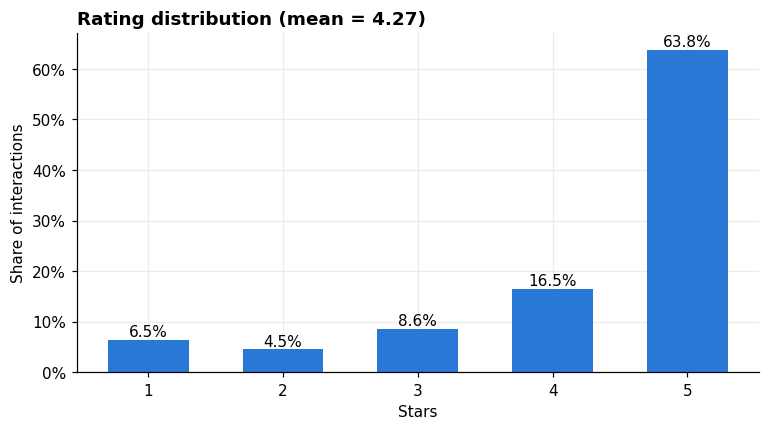

Average rating by product type:


,size,mean
product_type,,
Games,"404,476",4.24
Accessories,"264,943",4.26
Unknown,"93,545",4.34
Consoles,"28,968",4.43
Virtual Reality,"10,199",4.29
Online Game Services,"6,260",4.73
Downloadable Content,"6,195",3.86


In [12]:
# ==============================
# 5.2.3 Platforms and product types: share of catalog vs. share of interactions
# ==============================
inter["platform_family"] = inter["i"].map(info["platform_family"])
inter["product_type"] = inter["i"].map(info["product_type"]).fillna("Unknown")
inter["platform"] = inter["i"].map(info["platform"]).fillna("Unknown")
info["product_type"] = info["product_type"].fillna("Unknown")

def share_table(col, top_n=None):
    t = pd.DataFrame({
        "share_of_catalog": info[col].fillna("Unknown").value_counts(normalize=True),
        "share_of_interactions": inter[col].value_counts(normalize=True),
    }).fillna(0).sort_values("share_of_interactions", ascending=False)
    t["interactions_per_product"] = (t["share_of_interactions"] * len(inter)) / (t["share_of_catalog"] * N_ITEMS)
    return t.head(top_n) if top_n else t

fam_tbl, type_tbl, plat_tbl = share_table("platform_family"), share_table("product_type"), share_table("platform", 15)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, t, title in [(axes[0], fam_tbl, "Platform family"), (axes[1], type_tbl, "Product type"),
                     (axes[2], plat_tbl, "Platform (top 15 by interactions)")]:
    ax.barh(t.index[::-1], t["share_of_interactions"][::-1], color=BLUE, label="Share of interactions")
    ax.scatter(t["share_of_catalog"][::-1], t.index[::-1], color=ORANGE, zorder=3, label="Share of catalog")
    ax.set(title=f"{title}: interactions (bars) vs. catalog (dots)")
    pct_axis(ax, "x")
axes[0].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

fmt = {"share_of_catalog": "{:.1%}", "share_of_interactions": "{:.1%}", "interactions_per_product": "{:,.0f}"}
print("Product type:"); display(type_tbl.style.format(fmt))
print("Platform (top 15):"); display(plat_tbl.style.format(fmt))

# ==============================
# 5.2.4 Ratings (customer satisfaction)
# ==============================
fig, ax = plt.subplots(figsize=(8, 4))
rd = inter["rating"].value_counts(normalize=True).sort_index()
ax.bar(rd.index, rd.values, color=BLUE, width=0.6)
for x, v in zip(rd.index, rd.values):
    ax.text(x, v, f"{v:.1%}", ha="center", va="bottom")
ax.set(title=f"Rating distribution (mean = {inter['rating'].mean():.2f})", xlabel="Stars", ylabel="Share of interactions")
pct_axis(ax)
plt.show()

print("Average rating by product type:")
display(inter.groupby("product_type")["rating"].agg(["size", "mean"]).sort_values("size", ascending=False)
        .style.format({"size": "{:,}", "mean": "{:.2f}"}))

### 5.2 Products — Key Findings

**1. Popularity is concentrated, but the head is flat.**
- Interactions per product: median **12**, mean **31.8**, max **2,955**. The distribution is heavily right-skewed: every product has at least 5 interactions (5-core), and the 99th percentile is \~341.
- **Gini = 0.64**. The **top 1%** of products receive **19%** of interactions, the **top 5%** receive **42%**, and the **top 20%** receive **70%**.
- Even so, **the most popular product accounts for only 0.36%** of all interactions (an amFilm screen protector for the Switch). No single item dominates, so a pure popularity baseline will hit rarely: a top-10 list covers only \~2.5% of all interactions.

**2. The long tail is large and data-poor.**
- **40.6%** of products have fewer than 10 interactions, **67.8%** fewer than 20 and **86.7%** fewer than 50.
- Most item embeddings will be learned from a handful of sequences. Co-occurrence counts for these items will be sparse and noisy, so smoothing or shrinkage will matter for the unsupervised models.

**3. The top products mix games, accessories, consoles and subscriptions.**
- The top 15 include blockbuster games (GTA V, Skyrim VR, Fallout 4, Battlefield 3/4, Assassin's Creed IV, Far Cry 4), accessories (DualShock 4, Switch Pro Controller, screen protector), a console (PS4) and subscriptions (Xbox Live Gold, PlayStation Plus).
- Customers do not just buy games. They buy the **ecosystem around a platform**: hardware, controllers, protection and online services. This is a natural basis for sequential patterns (console → accessories → games).

**4. Metadata is useful but noisy.**
- Some top products are mislabeled. The PS4 console has no product type, Xbox Live Gold's "platform" is *Subscription Cards*, and Zelda BotW Master Edition is tagged as a *Console*. About 10.5% of the catalog has an unknown type.
- **Decision:** the core models will be **ID-based** (they learn from sequences alone). Metadata will be used for analysis and diagnostics, not as a required input.

**5. Platforms: current-generation consoles over-perform, PC under-performs.**

| Group | Share of catalog | Share of interactions | Interactions per product |
|---|---|---|---|
| PC | 24.8% | 18.9% | 24 |
| PlayStation 3 | 4.4% | 9.1% | **65** |
| Wii U | 1.1% | 2.1% | **63** |
| Xbox One / Xbox 360 | 5.6% / 5.4% | 8.6% / 8.1% | 48 / 48 |
| PlayStation 4 | 7.0% | 9.5% | 43 |
| Nintendo Switch | 8.8% | 8.4% | 30 |
| Older generations (PS1, PS2, Xbox, DS) | \~13% | \~9% | 20–25 |

- At the family level, **PlayStation (\~28% of interactions vs. \~23% of catalog)** and **Xbox (\~19% vs. \~14%)** punch above their weight. **PC (\~19% vs. \~25%)** and **Nintendo (\~27% vs. \~29%)** fall slightly below.
- PC has the largest catalog but the lowest engagement per product. A likely reason is that many PC games are sold through other stores (Steam, Epic) rather than as Amazon listings.

**6. Product types: games dominate, and services are tiny but intense.**
- **Games**: 44.7% of the catalog and 49.7% of interactions (35 per product). **Accessories**: 39.6% and 32.5% (26 per product).
- **Online Game Services** (0.1% of the catalog, **169 interactions per product**) and **Downloadable Content** (0.3% of the catalog, 70 per product) are very small, very popular categories: a few membership cards collect many purchases.
- **Virtual Reality** under-performs (2.4% of the catalog, 1.3% of interactions).

**7. Ratings are J-shaped and very positive.**
- **63.8%** of interactions are 5 stars and **80.3%** are 4–5 stars. The mean is **4.27**. Only **11.0%** are 1–2 stars.
- By type: Online Game Services score highest (**4.73**), then Consoles (4.43). **Downloadable Content** scores lowest (**3.86**), consistent with frequent complaints about paid add-ons.
- **Decision:** as in the official benchmark, every review is treated as an **implicit positive signal** (the customer bought and engaged with the product). Ratings are **not** the target here. We predict *which* product comes next, not how much the customer will like it.

**Implications for modeling:**
- **Popularity baseline**: expected to be weak because the head is flat. It is still a necessary reference point.
- **Item-to-item / transition models**: should exploit platform ecosystems (accessory → game on the same console), but need smoothing for the 40% of items with fewer than 10 interactions.
- **Sequential models (GRU4Rec, SASRec)**: must learn useful representations for many rare items. Regularization (dropout, weight decay) and full-catalog evaluation will reveal whether they go beyond recommending popular items.
- **Platform** looks like a strong contextual signal. Section 5.4 tests whether the next product usually shares the previous product's platform.

### 5.3 Time: How Does Behavior Change Over the Years?

**Questions:**
- How has activity evolved between 1999 and 2023? When do validation and test targets happen?
- Does the popular platform change over time (console generations)? This would make **recency** important.
- Is there seasonality (e.g., a holiday peak in December)?
- **Leakage check:** leave-one-out is *not* a global temporal split. How much training data comes *after* each user's test target?
- **Popularity drift:** do test targets match all-time best-sellers or the best-sellers *of their year*?

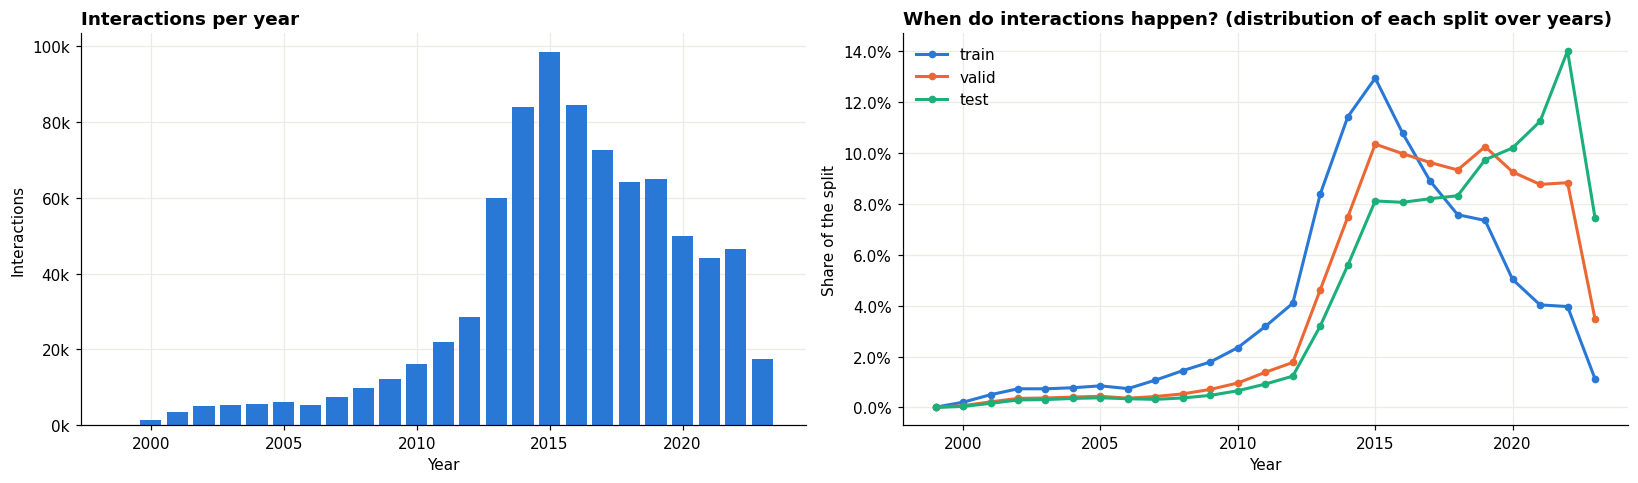

Median year — train: 2015 | valid: 2017 | test: 2019
Share of test targets from 2018 onward: 61.0%


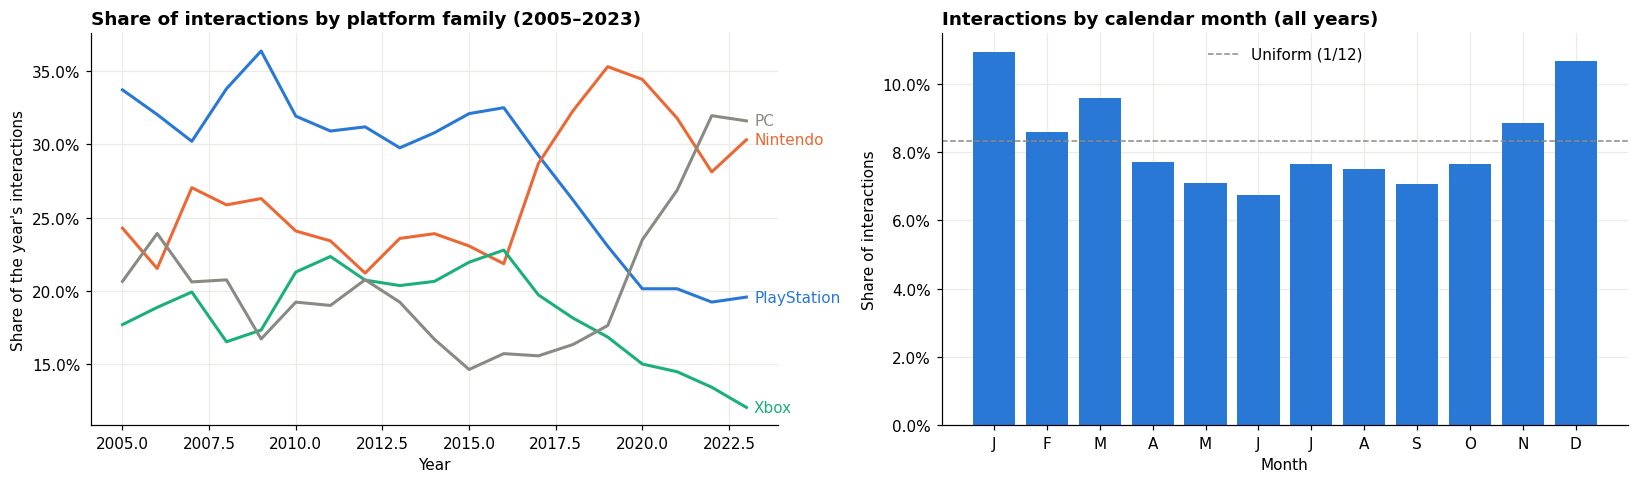

Peak month: 1 (10.9%) | lowest month: 6 (6.8%)


In [13]:
# ==============================
# 5.3.1 Activity over the years
# ==============================
inter["year"] = inter["datetime"].dt.year
inter["month"] = inter["datetime"].dt.month

per_year = inter.groupby(["year", "split"], observed=True).size().unstack(fill_value=0)
split_share_year = per_year / per_year.sum()                     # each split's distribution over years

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(per_year.index, per_year.sum(axis=1), color=BLUE)
axes[0].set(title="Interactions per year", xlabel="Year", ylabel="Interactions")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))

for s, c in zip(["train", "valid", "test"], [BLUE, ORANGE, GREEN]):
    axes[1].plot(split_share_year.index, split_share_year[s], color=c, lw=2, marker="o", ms=4, label=s)
axes[1].set(title="When do interactions happen? (distribution of each split over years)",
            xlabel="Year", ylabel="Share of the split")
axes[1].legend(frameon=False)
pct_axis(axes[1])
plt.tight_layout()
plt.show()

print("Median year — train: {:.0f} | valid: {:.0f} | test: {:.0f}".format(
    *[inter.loc[inter["split"] == s, "datetime"].dt.year.median() for s in ["train", "valid", "test"]]))
print("Share of test targets from 2018 onward: {:.1%}".format((inter.loc[inter['split'] == 'test', 'year'] >= 2018).mean()))

# ==============================
# 5.3.2 Platform families over time
# ==============================
fam_year = (inter[inter["year"].between(2005, 2023)]
            .groupby(["year", "platform_family"]).size().unstack(fill_value=0))
fam_year = fam_year.div(fam_year.sum(axis=1), axis=0)
fam_colors = {"PlayStation": BLUE, "Nintendo": ORANGE, "Xbox": GREEN, "PC": GREY}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for fam, c in fam_colors.items():
    axes[0].plot(fam_year.index, fam_year[fam], color=c, lw=2, label=fam)
    axes[0].annotate(fam, (fam_year.index[-1], fam_year[fam].iloc[-1]), xytext=(5, 0),
                     textcoords="offset points", va="center", color=c)
axes[0].set(title="Share of interactions by platform family (2005–2023)", xlabel="Year", ylabel="Share of the year's interactions")
pct_axis(axes[0])

# ==============================
# 5.3.3 Seasonality
# ==============================
by_month = inter["month"].value_counts(normalize=True).sort_index()
axes[1].bar(by_month.index, by_month.values, color=BLUE)
axes[1].axhline(1 / 12, color=GREY, ls="--", lw=1, label="Uniform (1/12)")
axes[1].set(title="Interactions by calendar month (all years)", xlabel="Month", ylabel="Share of interactions",
            xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"))
axes[1].legend(frameon=False)
pct_axis(axes[1])
plt.tight_layout()
plt.show()

print(f"Peak month: {by_month.idxmax()} ({by_month.max():.1%}) | lowest month: {by_month.idxmin()} ({by_month.min():.1%})")

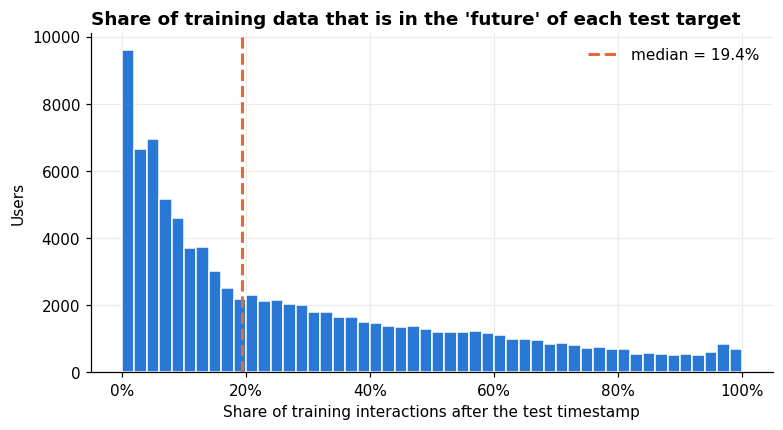

Test targets with >10% of training data in their future: 65.2%
Test targets with >50% of training data in their future: 21.9%

Test targets in the all-time top-100:      10.6%
Test targets in their own year's top-100: 22.7%
(Descriptive only: both lists include the targets themselves.)
Test targets whose product appeared <  30 days earlier: 11.8%
Test targets whose product appeared <  90 days earlier: 20.4%
Test targets whose product appeared < 365 days earlier: 41.2%


In [14]:
# ==============================
# 5.3.4 Leakage check: training interactions that happen AFTER each user's test target
# ==============================
train_ts = np.sort(inter.loc[inter["split"] == "train", "timestamp"].values)
test_rows = inter[inter["split"] == "test"]
future_share = 1 - np.searchsorted(train_ts, test_rows["timestamp"].values, side="right") / len(train_ts)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(future_share, bins=50, color=BLUE, edgecolor="white")
ax.axvline(np.median(future_share), color=ORANGE, ls="--", lw=2, label=f"median = {np.median(future_share):.1%}")
ax.set(title="Share of training data that is in the 'future' of each test target",
       xlabel="Share of training interactions after the test timestamp", ylabel="Users")
pct_axis(ax, "x")
ax.legend(frameon=False)
plt.show()

print(f"Test targets with >10% of training data in their future: {(future_share > 0.10).mean():.1%}")
print(f"Test targets with >50% of training data in their future: {(future_share > 0.50).mean():.1%}")

# ==============================
# 5.3.5 Popularity drift: all-time best-sellers vs. best-sellers of the target's year
# ==============================
TOP_N = 100
all_top = set(n_per_item.head(TOP_N).index)
year_top = (inter.groupby(["year", "i"]).size().rename("n").reset_index()
            .sort_values(["year", "n"], ascending=[True, False]).groupby("year").head(TOP_N))
year_top_set = set(zip(year_top["year"], year_top["i"]))

in_all = test_rows["i"].isin(all_top).mean()
in_year = np.mean([(y, i) in year_top_set for y, i in zip(test_rows["year"], test_rows["i"])])
print(f"\nTest targets in the all-time top-{TOP_N}:      {in_all:.1%}")
print(f"Test targets in their own year's top-{TOP_N}: {in_year:.1%}")
print("(Descriptive only: both lists include the targets themselves.)")

# Item life cycle: how old is a product (since its first interaction) when it becomes a test target?
first_seen = inter.groupby("i")["timestamp"].min()
age_days = (test_rows["timestamp"].values - test_rows["i"].map(first_seen).values) / 86_400_000
for d in (30, 90, 365):
    print(f"Test targets whose product appeared < {d:>3} days earlier: {(age_days < d).mean():.1%}")

### 5.3 Time — Key Findings

**1. Activity follows Amazon's growth, then declines.**
- Interactions grow slowly from 1999, accelerate after 2012, and **peak in 2015 (\~98k)**. They then fall to \~45–50k per year between 2020 and 2022. 2023 is partial (the data ends in September 2023).
- The 5-core filter partly explains the shape: recent users have had less time to reach 5 reviews, so they are under-represented.

**2. Validation and test targets are much more recent than training data.**
- Median year: **train 2015, valid 2017, test 2019**. **61.0%** of test targets happen in 2018 or later, and the test distribution peaks in 2022.
- This is expected, because targets are each user's *last* interactions. The model trains mostly on the 2013–2017 era and is evaluated mostly on the 2018–2023 era.

**3. The platform landscape changes with console generations.**
- **PlayStation** led from 2005 to 2016 (30–36% of each year's interactions), then fell to \~20% by 2020.
- **Nintendo** jumped from \~22% in 2016 to \~35% in 2019, driven by the **Switch** launch (2017).
- **PC** rose from \~16% in 2018 to \~32% in 2022. **Xbox** declined steadily from \~23% in 2016 to \~12% in 2023.
- What is "popular" depends heavily on *when* you look. A recommender that ignores time will keep pushing the previous generation's best-sellers.

**4. Seasonality: a post-holiday peak.**
- **January is the busiest month (10.9%)**, followed by December (\~10.7%) and March (\~9.6%). **June is the quietest (6.8%)** against a uniform 8.3%.
- The January peak reflects the review lag: holiday purchases and gifts are reviewed in the following weeks.

**5. Leakage: leave-one-out lets the model see the future.**
- For the median user, **19.4%** of all training interactions happen *after* their test target.
- **65.2%** of test targets have more than 10% of training data in their future, and **21.9%** have more than half.
- The model can therefore learn about products and trends that did not exist yet when the user made the decision. This is a **known limitation of the official benchmark** (and of most leave-one-out evaluations in the literature). Absolute metrics are optimistic. Comparisons between models remain fair, because every model sees the same data.

**6. Popularity drifts: recent popularity is twice as informative.**
- **10.6%** of test targets are in the **all-time top-100**, but **22.7%** are in the **top-100 of their own year**.
- Both lists include the targets themselves, so these are descriptive figures, not model scores. The gap is still clear: a time-aware popularity baseline should beat the all-time version.

**7. New releases matter.**
- **11.8%** of test targets were bought less than 30 days after the product's first interaction in the dataset, **20.4%** less than 90 days after and **41.2%** less than a year after.
- A large share of demand goes to **recently launched products**, which have little history for ID-based models to learn from. Sequential models get some help from recency: the last items in a user's history indicate the era and the platform generation they are in.

**Implications for modeling:**
- Add a **time-aware popularity baseline** (popularity in a window before the target) next to the all-time baseline.
- Sequence order and recency should matter more than a static user profile. Section 5.4 tests this directly.
- Report the leakage caveat alongside the results, and keep the official split so the results stay comparable with the literature.

### 5.4 Sequences: Does Order Matter?

**Questions:**
- Does the next product share the **platform family, platform, product type or store (publisher)** of the previous one, more than chance would predict?
- Does this coherence depend on the time gap (same-day sessions vs. purchases months apart)?
- What do **type-to-type transitions** look like (console → accessories → games)?
- Which predicts the test target's platform better: the **last item** or the user's **most frequent platform** in their history? If the last item wins, short-term sequential context matters more than a static profile, which is the core hypothesis behind GRU4Rec and SASRec.

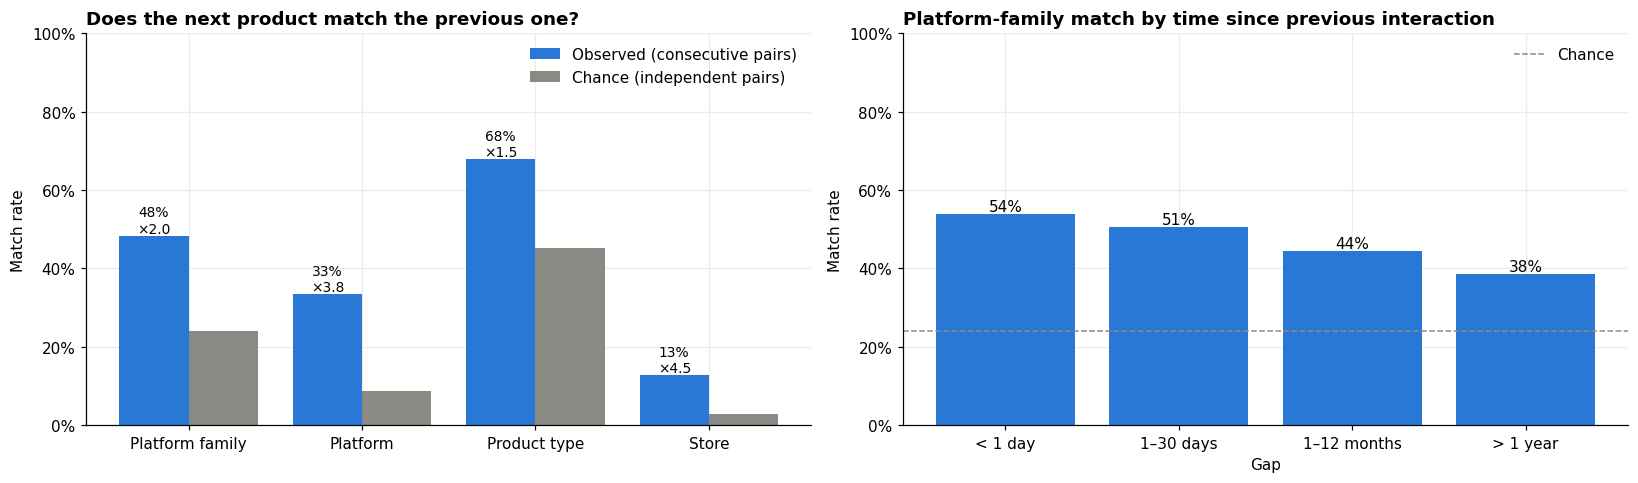

,observed,chance,lift,pairs
attribute,,,,
platform_family,48.4%,24.0%,2.0×,"676,897"
platform,33.4%,8.7%,3.8×,"676,897"
product_type,67.9%,45.2%,1.5×,"567,674"
store,12.8%,2.8%,4.5×,"716,631"


,mean,size
gap,,
< 1 day,53.8%,"287,947"
1–30 days,50.5%,"96,677"
1–12 months,44.4%,"190,480"
> 1 year,38.5%,"101,793"


In [15]:
# ==============================
# 5.4.1 Consecutive-pair coherence vs. chance
# ==============================
inter["store"] = inter["i"].map(info["store"])
ATTRS = ["platform_family", "platform", "product_type", "store"]

prev = inter.groupby("u")[ATTRS + ["i"]].shift(1)
has_prev = prev["i"].notna()

def is_known(s):
    return s.notna() & (s != "Unknown")

coh = []
for a in ATTRS:
    m = has_prev & is_known(inter[a]) & is_known(prev[a])
    observed = (inter.loc[m, a] == prev.loc[m, a]).mean()
    p = inter.loc[is_known(inter[a]), a].value_counts(normalize=True)
    chance = (p ** 2).sum()                     # probability that two independent interactions match
    coh.append({"attribute": a, "observed": observed, "chance": chance, "lift": observed / chance, "pairs": m.sum()})
coh = pd.DataFrame(coh).set_index("attribute")

# Coherence by time gap (platform family)
bins = [-0.01, 1, 30, 365, np.inf]
labels = ["< 1 day", "1–30 days", "1–12 months", "> 1 year"]
m = has_prev & is_known(inter["platform_family"]) & is_known(prev["platform_family"])
gap_tbl = (pd.DataFrame({"gap": pd.cut(inter.loc[m, "gap_days"], bins=bins, labels=labels),
                         "match": inter.loc[m, "platform_family"] == prev.loc[m, "platform_family"]})
           .groupby("gap", observed=True)["match"].agg(["mean", "size"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(coh))
axes[0].bar(x - 0.2, coh["observed"], width=0.4, color=BLUE, label="Observed (consecutive pairs)")
axes[0].bar(x + 0.2, coh["chance"], width=0.4, color=GREY, label="Chance (independent pairs)")
for xi, (o, l) in enumerate(zip(coh["observed"], coh["lift"])):
    axes[0].text(xi - 0.2, o, f"{o:.0%}\n×{l:.1f}", ha="center", va="bottom", fontsize=9)
axes[0].set(title="Does the next product match the previous one?", xticks=x,
            xticklabels=["Platform family", "Platform", "Product type", "Store"], ylabel="Match rate", ylim=(0, 1))
axes[0].legend(frameon=False)
pct_axis(axes[0])

axes[1].bar(gap_tbl.index.astype(str), gap_tbl["mean"], color=BLUE)
axes[1].axhline(coh.loc["platform_family", "chance"], color=GREY, ls="--", lw=1, label="Chance")
for xi, v in enumerate(gap_tbl["mean"]):
    axes[1].text(xi, v, f"{v:.0%}", ha="center", va="bottom")
axes[1].set(title="Platform-family match by time since previous interaction", xlabel="Gap", ylabel="Match rate", ylim=(0, 1))
axes[1].legend(frameon=False)
pct_axis(axes[1])
plt.tight_layout()
plt.show()

display(coh.style.format({"observed": "{:.1%}", "chance": "{:.1%}", "lift": "{:.1f}×", "pairs": "{:,}"}))
display(gap_tbl.style.format({"mean": "{:.1%}", "size": "{:,}"}))

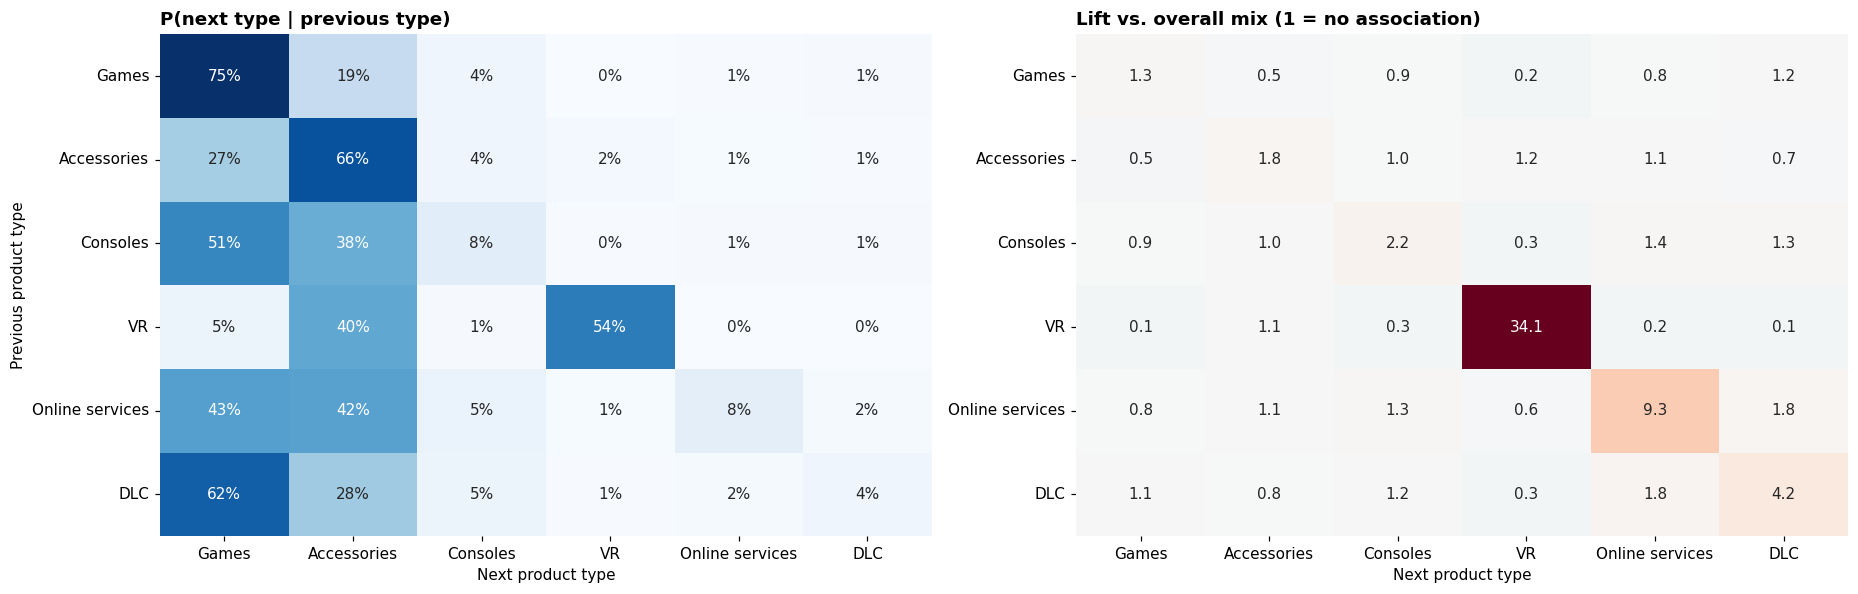

Test users evaluated: 88,574
Target family = family of LAST item:          46.9%
Target family = user's MOST FREQUENT family:  49.4%

When last item and profile disagree (37.4% of users):
  target follows the last item: 29.8%
  target follows the profile:   36.4%


In [16]:
# ==============================
# 5.4.2 Type-to-type transitions
# ==============================
types = ["Games", "Accessories", "Consoles", "Virtual Reality", "Online Game Services", "Downloadable Content"]
m = has_prev & inter["product_type"].isin(types) & prev["product_type"].isin(types)
trans = pd.crosstab(prev.loc[m, "product_type"], inter.loc[m, "product_type"], normalize="index").reindex(index=types, columns=types)
base = inter.loc[m, "product_type"].value_counts(normalize=True).reindex(types)
trans_lift = trans / base                                   # >1: this transition is more frequent than the overall mix

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
short = ["Games", "Accessories", "Consoles", "VR", "Online services", "DLC"]
sns.heatmap(trans, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=axes[0], xticklabels=short, yticklabels=short)
axes[0].set(title="P(next type | previous type)", xlabel="Next product type", ylabel="Previous product type")
sns.heatmap(trans_lift, annot=True, fmt=".1f", cmap="RdBu_r", center=1, cbar=False, ax=axes[1], xticklabels=short, yticklabels=short)
axes[1].set(title="Lift vs. overall mix (1 = no association)", xlabel="Next product type", ylabel="")
plt.tight_layout()
plt.show()

# ==============================
# 5.4.3 Last item vs. user profile: which predicts the test target's platform family?
# ==============================
hist = inter[(inter["split"] != "test") & is_known(inter["platform_family"])]
cnt = hist.groupby(["u", "platform_family"]).size()
mode_fam = cnt.groupby(level=0).idxmax().str[1]              # user's most frequent family in history

t = inter[inter["split"] == "test"].copy()
t["last_fam"] = prev.loc[t.index, "platform_family"]
t["mode_fam"] = t["u"].map(mode_fam)
ok = is_known(t["platform_family"]) & is_known(t["last_fam"]) & t["mode_fam"].notna()
t = t[ok]

last_hit = (t["platform_family"] == t["last_fam"]).mean()
mode_hit = (t["platform_family"] == t["mode_fam"]).mean()
agree = t["last_fam"] == t["mode_fam"]
print(f"Test users evaluated: {len(t):,}")
print(f"Target family = family of LAST item:          {last_hit:.1%}")
print(f"Target family = user's MOST FREQUENT family:  {mode_hit:.1%}")
print(f"\nWhen last item and profile disagree ({(~agree).mean():.1%} of users):")
print(f"  target follows the last item: {(t.loc[~agree, 'platform_family'] == t.loc[~agree, 'last_fam']).mean():.1%}")
print(f"  target follows the profile:   {(t.loc[~agree, 'platform_family'] == t.loc[~agree, 'mode_fam']).mean():.1%}")

### 5.4 Sequences — Key Findings

**1. Consecutive products are strongly related: order carries signal.**

| Attribute | Observed match | Chance | Lift |
|---|---|---|---|
| Platform family | 48.4% | 24.0% | **2.0×** |
| Platform (specific console) | 33.4% | 8.7% | **3.8×** |
| Product type | 67.9% | 45.2% | **1.5×** |
| Store (publisher / brand) | 12.8% | 2.8% | **4.5×** |

- Every attribute matches well above chance. The more specific the attribute, the higher the lift. The **specific platform** (3.8×) is far more informative than the platform family (2.0×). Customers stay within a **console generation**, not just a brand.
- **Store** has the highest lift (4.5×), which suggests **publisher or brand loyalty** (the same studio's games, or the same accessory brand).

**2. Coherence decays with time.**
- Platform-family match is **53.8%** for interactions on the same day, **50.5%** within a month, **44.4%** within a year and **38.5%** after more than a year. It stays above the 24% chance level throughout.
- Same-day interactions (\~288k pairs) behave like a **shopping session**: highly coherent purchases for the same console. Long gaps often mean the customer changed console generation in between.

**3. Customers buy in "streaks" of the same type.**
- The diagonal dominates the transition matrix. Games → Games is **75%** and Accessories → Accessories is **66%**.
- Relative to the overall mix, the strongest self-transitions are **VR → VR (54%, lift 34×)**, **Online services → Online services (lift 9.3×)** and **DLC → DLC (lift 4.2×)**: niche categories attract repeat buyers within the niche.
- Cross-type links are weaker than expected. **Consoles → Games (51%) / Accessories (38%)** have lift \~1, so buying a console does not specifically trigger accessories. Games → Accessories is *under*-represented (lift 0.5). Two niche cross-links do stand out: **Online services ↔ DLC (lift 1.8×)** and **Consoles → Online services (1.4×)**, the console → subscription pattern.

**4. Surprise: the long-term profile beats the last item for the test target.**
- Target family = family of the **last item**: **46.9%**. Target family = the user's **most frequent family**: **49.4%**.
- When the two disagree (37.4% of users), the target follows the **profile 36.4%** of the time vs. the **last item 29.8%**.
- This is consistent with finding 2. The test gap has a median of 79 days, and coherence with the last item weakens over long gaps. For most test targets, the user's long-term "home platform" is a better guide than their last purchase.

**Implications for modeling:**
- The core hypothesis is **only partly supported**. Sequential context matters (all lifts > 1, strong same-session coherence), but a **static profile is also needed**.
- This favors models that **attend to the full history** (SASRec, through self-attention) over models dominated by the most recent step (a pure last-item Markov chain, or GRU4Rec with very short histories).
- Expect last-item transition models to do well for users whose test target falls in the **same session** (\~31% interact within the hour), and worse for long gaps. Results will be broken down by gap in Section 7.

### 5.5 Co-occurrence and Transitions: How Much Item-to-Item Signal Is There?

**Questions:**
- How sparse is the item-to-item graph? How many product pairs are observed only once?
- **Ceiling of item-to-item models:** how often has the validation target *ever* followed the user's last training item?
- **Quick preview:** how does a simple "top-10 successors of the last item" rule compare with popularity? Does a symmetric **co-occurrence window** (items close in the sequence, in either order) beat strict **directed transitions**?
- Which product pairs are most strongly linked?

*To keep the test set untouched, transitions are built from **training interactions only** and checked against **validation targets**.*

Directed transitions: 530,300 pairs | 469,362 distinct (0.0716% of all possible pairs)
  seen only once: 92.8% of distinct pairs
  items with ≥1 successor: 99.0% | median successors per item: 8
Co-occurrence (±3): 2,082,142 distinct pairs | seen only once: 88.3%


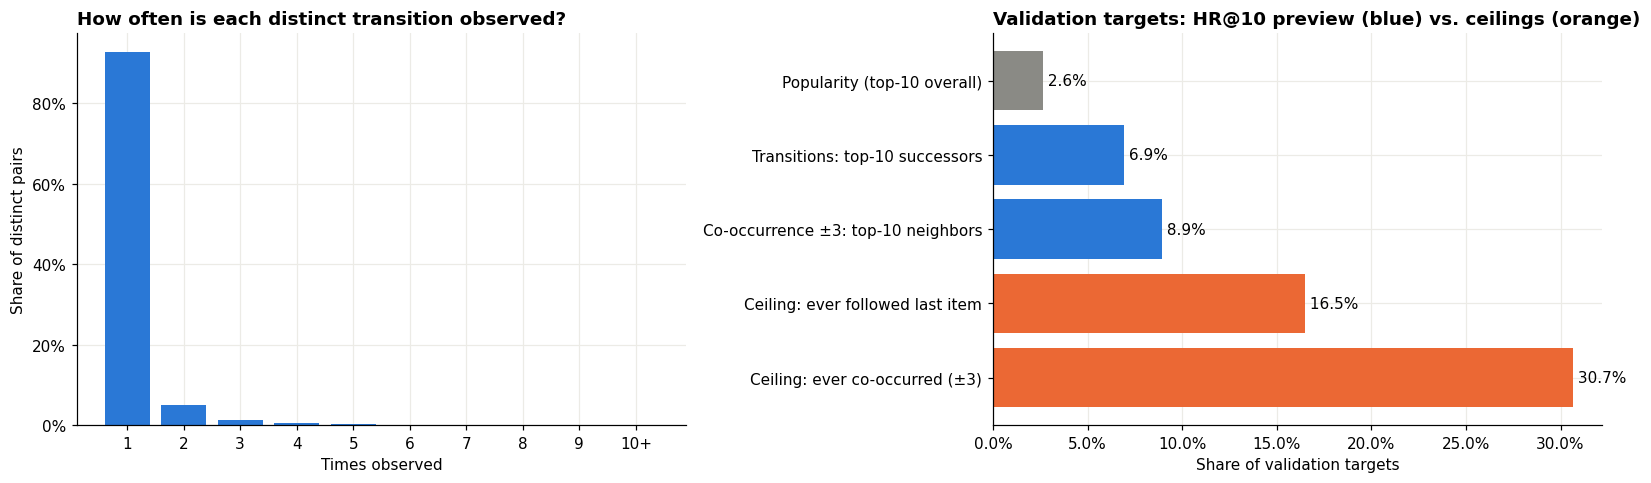

,share_of_valid_targets
Popularity (top-10 overall),2.62%
Transitions: top-10 successors,6.93%
Co-occurrence ±3: top-10 neighbors,8.93%
Ceiling: ever followed last item,16.50%
Ceiling: ever co-occurred (±3),30.67%


In [17]:
# ==============================
# 5.5.1 Directed transitions (a → next b) and co-occurrence window (±3, both directions), train only
# ==============================
tr = inter[inter["split"] == "train"]
g = tr.groupby("u")["i"]

trans_pairs = pd.DataFrame({"a": tr["i"], "b": g.shift(-1)}).dropna().astype("int32")
trans_cnt = trans_pairs.value_counts().rename("n").reset_index()

WINDOW = 3
co_parts = []
for k in range(1, WINDOW + 1):
    nb = g.shift(-k)
    p = pd.DataFrame({"a": tr["i"], "b": nb}).dropna().astype("int32")
    co_parts += [p, p.rename(columns={"a": "b", "b": "a"})]             # both directions
co_cnt = pd.concat(co_parts, ignore_index=True).value_counts().rename("n").reset_index()

print(f"Directed transitions: {len(trans_pairs):,} pairs | {len(trans_cnt):,} distinct "
      f"({len(trans_cnt) / (N_ITEMS ** 2):.4%} of all possible pairs)")
print(f"  seen only once: {(trans_cnt['n'] == 1).mean():.1%} of distinct pairs")
out_deg = trans_cnt.groupby("a").size()
print(f"  items with ≥1 successor: {len(out_deg) / N_ITEMS:.1%} | median successors per item: {out_deg.median():.0f}")
print(f"Co-occurrence (±{WINDOW}): {len(co_cnt):,} distinct pairs | seen only once: {(co_cnt['n'] == 1).mean():.1%}")

# ==============================
# 5.5.2 Validation preview: last training item → validation target
# ==============================
last_item = g.last()
valid_t = inter[inter["split"] == "valid"].set_index("u")["i"]
q = pd.DataFrame({"a": last_item.reindex(valid_t.index).values, "b": valid_t.values})

def hit_rate(cnt, k=None):
    pool = cnt if k is None else cnt.sort_values(["a", "n"], ascending=[True, False]).groupby("a").head(k)
    return q.merge(pool[["a", "b"]], on=["a", "b"], how="left", indicator=True)["_merge"].eq("both").mean()

K = 10
pop_top = tr["i"].value_counts().head(K).index
res = pd.Series({
    "Popularity (top-10 overall)": valid_t.isin(pop_top).mean(),
    "Transitions: top-10 successors": hit_rate(trans_cnt, K),
    f"Co-occurrence ±{WINDOW}: top-10 neighbors": hit_rate(co_cnt, K),
    "Ceiling: ever followed last item": hit_rate(trans_cnt),
    f"Ceiling: ever co-occurred (±{WINDOW})": hit_rate(co_cnt),
})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
nb = trans_cnt["n"].clip(upper=10).value_counts(normalize=True).sort_index()
axes[0].bar(nb.index.astype(str).str.replace("10", "10+"), nb.values, color=BLUE)
axes[0].set(title="How often is each distinct transition observed?", xlabel="Times observed", ylabel="Share of distinct pairs")
pct_axis(axes[0])

colors = [GREY, BLUE, BLUE, ORANGE, ORANGE]
axes[1].barh(res.index[::-1], res.values[::-1], color=colors[::-1])
for y, v in enumerate(res.values[::-1]):
    axes[1].text(v, y, f" {v:.1%}", va="center")
axes[1].set(title="Validation targets: HR@10 preview (blue) vs. ceilings (orange)", xlabel="Share of validation targets")
pct_axis(axes[1], "x")
plt.tight_layout()
plt.show()

display(res.to_frame("share_of_valid_targets").style.format("{:.2%}"))

In [18]:
# ==============================
# 5.5.3 Strongest links: conditional probability P(next = b | current = a), minimum support
# ==============================
MIN_SUPPORT = 30
a_tot = trans_pairs["a"].value_counts()
strong = trans_cnt[trans_cnt["n"] >= MIN_SUPPORT].copy()
strong["p_next"] = strong["n"] / strong["a"].map(a_tot)
strong["lift"] = strong["p_next"] / strong["b"].map(tr["i"].value_counts(normalize=True))

def titled(df):
    out = df.copy()
    out["from"] = out["a"].map(info["title"]).str.slice(0, 55)
    out["to"] = out["b"].map(info["title"]).str.slice(0, 55)
    return out[["from", "to", "n", "p_next", "lift"]]

fmt = {"n": "{:,}", "p_next": "{:.1%}", "lift": "{:,.0f}"}
print(f"Most frequent transitions (n ≥ {MIN_SUPPORT}):")
display(titled(strong.nlargest(10, "n")).style.format(fmt).hide(axis="index"))
print(f"Highest conditional probability P(b | a) (n ≥ {MIN_SUPPORT}):")
display(titled(strong.nlargest(10, "p_next")).style.format(fmt).hide(axis="index"))

Most frequent transitions (n ≥ 30):


from,to,n,p_next,lift
DualShock 4 Wireless Controller for PlayStation 4 - Jet,PlayStation 4 500GB Console [Old Model][Discontinued],76,10.9%,44
The Legend of Zelda: Breath of the Wild Master Edition,amFilm Tempered Glass Screen Protector for Nintendo Swi,60,7.0%,21
amFilm Tempered Glass Screen Protector for Nintendo Swi,The Legend of Zelda: Breath of the Wild Master Edition,53,3.3%,19
PlayStation 4 500GB Console [Old Model][Discontinued],DualShock 4 Wireless Controller for PlayStation 4 - Jet,48,3.5%,26
Mario Kart 8 Deluxe – Booster Course Pass - Nintendo Sw,The Legend of Zelda: Breath of the Wild Master Edition,41,7.6%,43
PlayStation 4 500GB Console [Old Model][Discontinued],Battlefield 4 - Playstation 3,41,3.0%,15
Nintendo Switch Pro Controller,The Legend of Zelda: Breath of the Wild Master Edition,38,5.2%,30
Fallout 4 - Xbox One,Star Wars Battlefront Outer Rim - Xbox One Digital Code,38,3.6%,25
Nintendo 3DS Compatible with 3DS / 3DS XL / 2DS AC Adap,Nintendo New 3DS XL - Galaxy Style,38,11.0%,159
Nintendo Switch Pro Controller,amFilm Tempered Glass Screen Protector for Nintendo Swi,37,5.0%,15


Highest conditional probability P(b | a) (n ≥ 30):


from,to,n,p_next,lift
Steam Link,Steam Controller,31,13.5%,242
Knack (PlayStation 4),Killzone: Shadow Fall (PlayStation 4),30,12.0%,147
Nintendo 3DS Compatible with 3DS / 3DS XL / 2DS AC Adap,Nintendo New 3DS XL - Galaxy Style,38,11.0%,159
DualShock 4 Wireless Controller for PlayStation 4 - Jet,PlayStation 4 500GB Console [Old Model][Discontinued],76,10.9%,44
Orzly Carrying case for Nintendo Switch OLED and Switch,amFilm Tempered Glass Screen Protector for Nintendo Swi,32,9.3%,28
Super Mario 3D Land,Mario Kart 7,31,8.9%,133
Mario Kart 8 Deluxe – Booster Course Pass - Nintendo Sw,The Legend of Zelda: Breath of the Wild Master Edition,41,7.6%,43
"Remote Plus, Mario - Nintendo Wii",Nintendo Nunchuk Controller - White,30,7.6%,210
The Legend of Zelda: Breath of the Wild Master Edition,amFilm Tempered Glass Screen Protector for Nintendo Swi,60,7.0%,21
Mario Kart 8 Deluxe – Booster Course Pass - Nintendo Sw,Super Mario Odyssey - Nintendo Switch,32,5.9%,51


## 6. EDA Summary and Modeling Plan

### 6.1 What the EDA Tells Us

| # | Finding | Modeling decision |
|---|---|---|
| 1 | Short sequences (median 6, 32% of users have exactly 5); 99.5% fit in 50 items | `MAX_LEN = 50` for neural models; segment results by history length |
| 2 | No repeated purchases | Always **exclude the user's history** from recommendations |
| 3 | Flat head (top item = 0.36%), Gini 0.64, 40% of items with < 10 interactions | Popularity is a weak but necessary baseline; track **coverage** and **long-tail share** |
| 4 | Popularity drifts with console generations (top-100 of the year is 2× as informative as all-time) | Add a **time-aware popularity** baseline |
| 5 | Leave-one-out leaks the future (median 19.4% of training data is after the test target) | Keep the official split for comparability, and report the caveat |
| 6 | Consecutive items share platform (3.8×) and store (4.5×); coherence decays with time | Order and proximity matter; **segment results by time gap** |
| 7 | Long-term profile beats the last item for the test target (49.4% vs. 46.9%) | Use the **whole history**, not only the last step |
| 8 | Co-occurrence ±3 beats directed transitions (8.9% vs. 6.9% HR@10); ceiling 30.7% | Symmetric windows, normalization, multi-item aggregation; neural models to generalize |

### 6.2 Models

| ID | Model | Paradigm | Idea |
|---|---|---|---|
| M0 | Popularity (all-time) | Baseline | Most popular items not yet seen |
| M1 | Recent popularity | Baseline | Most popular items in the *W* months before the target |
| M2 | Markov transitions | Unsupervised | Successors of the last item |
| M3 | Sequential item-kNN | Unsupervised | Normalized co-occurrence neighbors of the last *L* items, with recency decay |
| M4 | GRU4Rec | Self-supervised | Recurrent network that predicts the next item from the sequence |
| M5 | SASRec | Self-supervised | Transformer with causal self-attention over the whole history |

### 6.3 Evaluation Protocol
- **Leave-one-out** (official benchmark): tune on **validation** (history = train), and report on **test** (history = train + valid).
- **Full-catalog ranking** over all 25,612 products (no negative sampling, which inflates metrics), excluding items already in the user's history.
- **Metrics:** HR@10, NDCG@10, HR@20 and NDCG@20, plus **coverage@10** (share of the catalog ever recommended) and **tail share@10** (share of recommendations outside the top 20% most popular items).
- Ties in scores are resolved by **expected rank** (no optimistic tie-breaking).
- Results are broken down by **history length** and **time gap** before the target.

## 7. Modeling

### 7.0 Evaluation Framework
One shared function evaluates every model. A model is a **scoring function**: given a batch of users, it returns a score for every product. The framework masks padding and history items, computes the target's rank, and stores per-user ranks for the segment analysis.

In [19]:
# ==============================
# 7.0 Evaluation framework (shared by all models)
# ==============================
inter["month_idx"] = ((inter["datetime"].dt.year - inter["datetime"].dt.year.min()) * 12
                      + inter["datetime"].dt.month - 1).astype("int32")
N_MONTHS = int(inter["month_idx"].max()) + 1

HIST_SPLITS = {"valid": ["train"], "test": ["train", "valid"]}
EVAL = {}
for s, hs in HIST_SPLITS.items():
    hist = inter[inter["split"].isin(hs)].groupby("u")["i"].apply(np.array)
    t = inter[inter["split"] == s].set_index("u").sort_index()
    h = hist.reindex(t.index).values
    EVAL[s] = {"users": t.index.values, "hist": h, "target": t["i"].values.astype(np.int64),
               "month": t["month_idx"].values, "gap": t["gap_days"].values,
               "hist_len": np.array([len(x) for x in h])}
    print(f"{s:>5}: {len(t):,} users | history = {' + '.join(hs)} | median history length = {np.median(EVAL[s]['hist_len']):.0f}")

# Head items = top 20% by training popularity (used for the long-tail metric)
train_pop = np.bincount(inter.loc[inter["split"] == "train", "i"], minlength=N_ITEMS + 1)
is_head = np.zeros(N_ITEMS + 1, dtype=bool)
is_head[np.argsort(-train_pop)[: int(0.2 * N_ITEMS)]] = True

RESULTS, RANKS = [], {}

def evaluate(name, split, score_fn, batch_size=1024, ks=(10, 20), store=True):
    """score_fn(idx) -> array (len(idx), N_ITEMS + 1) of scores for the users at positions idx of EVAL[split]."""
    E = EVAL[split]
    n = len(E["target"])
    ranks = np.empty(n, dtype=np.float32)
    recs = []
    for start in range(0, n, batch_size):
        idx = np.arange(start, min(start + batch_size, n))
        S = np.array(score_fn(idx), dtype=np.float32, copy=True)
        S[:, 0] = -np.inf                                                   # padding index
        rows = np.repeat(np.arange(len(idx)), [len(x) for x in E["hist"][idx]])
        S[rows, np.concatenate(E["hist"][idx])] = -np.inf                   # never recommend seen items
        t = S[np.arange(len(idx)), E["target"][idx]][:, None]
        ranks[idx] = (S > t).sum(1) + ((S == t).sum(1) - 1) / 2             # expected rank under random tie-breaking
        recs.append(np.argpartition(-S, 10, axis=1)[:, :10])
    recs = np.concatenate(recs)

    out = {"model": name, "split": split}
    for k in ks:
        hit = ranks < k
        out[f"HR@{k}"] = hit.mean()
        out[f"NDCG@{k}"] = np.where(hit, 1 / np.log2(ranks + 2), 0).mean()
    out["coverage@10"] = len(np.unique(recs)) / N_ITEMS
    out["tail_share@10"] = 1 - is_head[recs].mean()
    if store:
        RESULTS[:] = [r for r in RESULTS if not (r["model"] == name and r["split"] == split)]
        RESULTS.append(out)
        RANKS[(name, split)] = ranks
    return out

def show_results(split=None):
    df = pd.DataFrame(RESULTS)
    if split:
        df = df[df["split"] == split]
    metric_cols = [c for c in df.columns if c.startswith(("HR", "NDCG"))]
    display(df.set_index(["model", "split"]).style
            .format("{:.4f}", subset=metric_cols)
            .format("{:.1%}", subset=["coverage@10", "tail_share@10"]))

# Sanity check: a random scorer should give HR@10 ≈ 10 / N_ITEMS
rng = np.random.default_rng(SEED)
r = evaluate("Random", "valid", lambda idx: rng.random((len(idx), N_ITEMS + 1)), store=False)
print(f"\nRandom scorer HR@10 = {r['HR@10']:.4%} (expected ≈ {10 / N_ITEMS:.4%})")

valid: 94,762 users | history = train | median history length = 4
 test: 94,762 users | history = train + valid | median history length = 5

Random scorer HR@10 = 0.0359% (expected ≈ 0.0390%)


### 7.1 Baselines: All-Time vs. Recent Popularity (M0, M1)

- **M0** ranks products by their total number of interactions in the history splits.
- **M1** ranks products by their interactions in the **W months before the target's month**. Unlike M0, it uses no information from the future, so it is free of the leakage described in 5.3. The window **W** is tuned on validation. All-time popularity is added with a tiny weight to break ties.

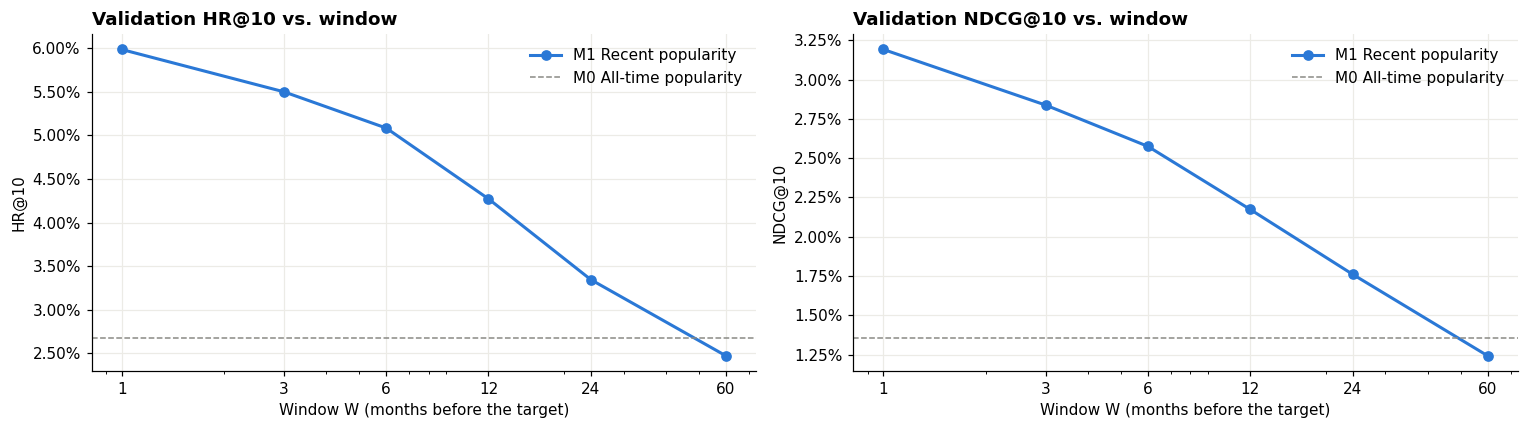

Best window: W = 1 months


In [20]:
# ==============================
# 7.1 Popularity baselines
# ==============================
def monthly_cum(hist_splits):
    """C[k] = interactions per item in months < k (history splits only)."""
    h = inter[inter["split"].isin(hist_splits)]
    M = np.zeros((N_MONTHS + 1, N_ITEMS + 1), dtype=np.float32)
    np.add.at(M, (h["month_idx"].values + 1, h["i"].values), 1)
    return M.cumsum(axis=0)

CUM = {s: monthly_cum(hs) for s, hs in HIST_SPLITS.items()}

def pop_scorer(split):
    counts = CUM[split][-1]
    return lambda idx: np.tile(counts, (len(idx), 1))

def recent_pop_scorer(split, W):
    C, E = CUM[split], EVAL[split]
    tie = 1e-3 * C[-1] / C[-1].max()
    def f(idx):
        m = E["month"][idx]
        return C[m] - C[np.maximum(m - W, 0)] + tie
    return f

# M0
for s in ["valid", "test"]:
    evaluate("M0 Popularity (all-time)", s, pop_scorer(s))

# M1: tune the window on validation
windows = [1, 3, 6, 12, 24, 60]
tune = pd.DataFrame([evaluate(f"W={W}", "valid", recent_pop_scorer("valid", W), store=False) for W in windows])
tune["W"] = windows
best_W = int(tune.loc[tune["NDCG@10"].idxmax(), "W"])

m0 = next(r for r in RESULTS if r["model"].startswith("M0") and r["split"] == "valid")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, met in zip(axes, ["HR@10", "NDCG@10"]):
    ax.plot(tune["W"], tune[met], color=BLUE, lw=2, marker="o", label="M1 Recent popularity")
    ax.axhline(m0[met], color=GREY, ls="--", lw=1, label="M0 All-time popularity")
    ax.set(xscale="log", xticks=windows, xticklabels=windows, title=f"Validation {met} vs. window",
           xlabel="Window W (months before the target)", ylabel=met)
    ax.legend(frameon=False)
    pct_axis(ax)
plt.tight_layout()
plt.show()
print(f"Best window: W = {best_W} months")

for s in ["valid", "test"]:
    evaluate(f"M1 Recent popularity (W={best_W}m)", s, recent_pop_scorer(s, best_W))
show_results()

### 7.1 Popularity Baselines — Key Findings

| Model | Split | HR@10 | NDCG@10 | HR@20 | NDCG@20 | Coverage@10 | Tail share@10 |
|---|---|---|---|---|---|---|---|
| M0 Popularity (all-time) | valid | 2.68% | 0.0136 | 4.15% | 0.0173 | 0.1% | 0.0% |
| M0 Popularity (all-time) | test | 2.49% | 0.0127 | 3.80% | 0.0160 | 0.1% | 0.0% |
| M1 Recent popularity (W = 1 month) | valid | **5.99%** | **0.0319** | 8.91% | 0.0393 | 5.9% | 6.5% |
| M1 Recent popularity (W = 1 month) | test | **6.03%** | **0.0318** | 8.87% | 0.0390 | 5.7% | 8.4% |

**1. Recency more than doubles the value of popularity.**
- M1 reaches **HR@10 = 6.0%** vs. 2.5–2.7% for M0 (**2.2–2.4×**), and NDCG@10 rises from 0.013 to 0.032 (**2.5×**). This confirms the popularity drift found in 5.3.
- Validation and test results are almost identical, so the tuned window generalizes.

**2. The shorter the window, the better.**
- Performance drops steadily as the window grows: HR@10 is 6.0% at W = 1 month, 4.3% at 12 months and 2.5% at 60 months.
- The best value (W = 1) is at the edge of the grid. A window of days or weeks could do even better, which shows how quickly demand moves (new releases, holiday seasons).

**3. M1 wins even though M0 sees the future.**
- M0 counts *all* history interactions, including those after the target (the leakage from 5.3). M1 only uses months strictly before the target month.
- With a 60-month window, M1 falls slightly *below* M0 (2.5% vs. 2.7%). This is the point where M0's look-ahead stops being outweighed by M1's recency.

**4. Popularity models do not personalize.**
- M0 recommends essentially the same 10 products to everyone: **coverage 0.1%** (\~26 products after removing each user's history) and **0% long tail**.
- M1 varies the list by month: coverage rises to **\~6%** and 6–8% of recommendations come from the long tail. It is still the same list for every user in the same month.

**Reference point:** any personalized model must beat **HR@10 ≈ 6.0% / NDCG@10 ≈ 0.032** (M1), not only M0.

### 7.2 Unsupervised Item-to-Item Models (M2, M3)

Both models are **unsupervised**: they learn nothing by optimization. They count which products appear close together in customers' sequences.

- **M2 — Markov transitions (first order).** Score(b) = number of times b *directly followed* the user's last item a. This is the directed-transition rule from 5.5, now with proper history masking.
- **M3 — Sequential item-kNN.** Addresses the four limitations found in the EDA:
  1. **Symmetric window** of ±*w* positions, with weights 1/distance (same-session order is arbitrary).
  2. **Popularity normalization:** sim(a, b) = C(a, b) / (pop(a)^(1−β) · pop(b)^β). β = 0 gives the conditional probability P(b | a), which favors popular items. β = 0.5 gives cosine similarity. β = 1 favors rare items.
  3. **Multi-item aggregation** over the user's last *L* items, so that more of the history is used.
  4. **Recency decay**: the item at distance *d* from the end weighs decay^*d*.

**Fallback:** both models rank their candidates first, then fill the rest of the list with **M1 recent popularity**.

**Tuning:** greedy search over (window, β, L, decay) on a random subsample of 30,000 validation users. The test set is used only once, with the final configuration.

In [21]:
# ==============================
# 7.2 Shared utilities: item-pair matrices, fallback, tuning subsample
# ==============================
from functools import lru_cache
from scipy import sparse

def base(split):
    """Which history builds the item statistics: train for valid/tune, train+valid for test."""
    return "test" if split == "test" else "valid"

# Tuning subsample (30k validation users); same history and statistics as "valid"
tune_idx = np.sort(np.random.default_rng(SEED).choice(len(EVAL["valid"]["target"]), 30_000, replace=False))
EVAL["tune"] = {k: v[tune_idx] for k, v in EVAL["valid"].items()}
CUM["tune"] = CUM["valid"]

@lru_cache(maxsize=None)
def pair_matrix(hist_split, window, directed):
    """Item × item matrix of (1/distance)-weighted pair counts within `window` positions of the history sequences."""
    seqs = EVAL[hist_split]["hist"]
    flat = np.concatenate(seqs)
    uid = np.repeat(np.arange(len(seqs)), [len(s) for s in seqs])
    rows, cols, vals = [], [], []
    for d in range(1, window + 1):
        same = uid[:-d] == uid[d:]
        a, b = flat[:-d][same], flat[d:][same]
        w = np.full(len(a), 1.0 / d, dtype=np.float32)
        rows.append(a); cols.append(b); vals.append(w)
        if not directed:
            rows.append(b); cols.append(a); vals.append(w)
    return sparse.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
                             shape=(N_ITEMS + 1, N_ITEMS + 1), dtype=np.float32)    # duplicates are summed

def with_fallback(scores, fb):
    """Rank model candidates (score > 0) first, by score; fill the rest with the fallback order."""
    fbn = fb / (fb.max(axis=1, keepdims=True) + 1e-12)                  # in [0, 1]
    mx = scores.max(axis=1, keepdims=True)
    mx[mx == 0] = 1
    return np.where(scores > 0, 1 + scores / mx, fbn)                    # candidates always > 1

# ==============================
# 7.2.1 M2 — Markov transitions
# ==============================
def markov_scorer(split):
    T = pair_matrix(base(split), 1, True)
    E, fb = EVAL[split], recent_pop_scorer(split, best_W)
    def f(idx):
        last = np.array([h[-1] for h in E["hist"][idx]])
        return with_fallback(T[last].toarray(), fb(idx))
    return f

for s in ["valid", "test"]:
    evaluate("M2 Markov transitions", s, markov_scorer(s))
show_results()

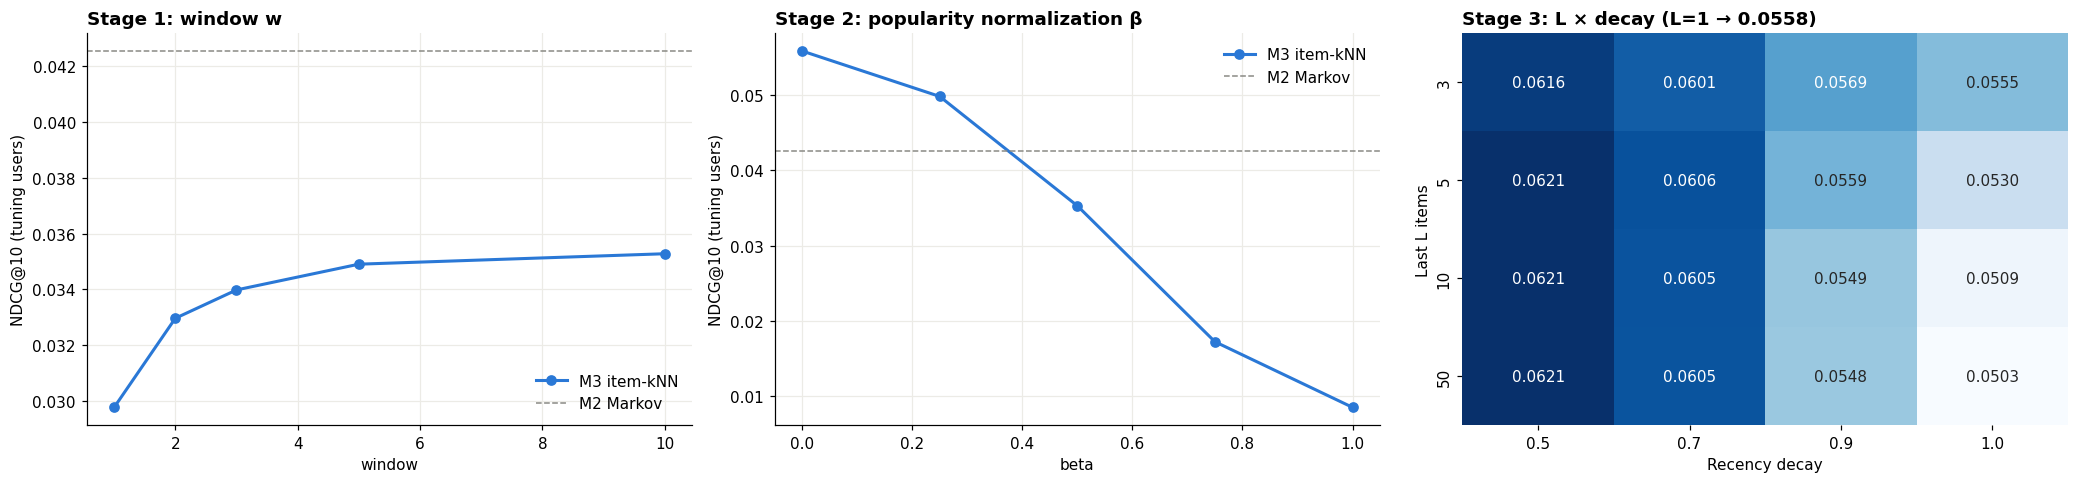

Best M3 configuration: {'window': 10, 'beta': 0.0, 'L': 50, 'decay': 0.5}


In [22]:
# ==============================
# 7.2.2 M3 — Sequential item-kNN
# ==============================
def knn_scorer(split, window, beta, L, decay):
    hs = base(split)
    pop = np.bincount(np.concatenate(EVAL[hs]["hist"]), minlength=N_ITEMS + 1).astype(np.float32)
    pop[pop == 0] = 1
    C = pair_matrix(hs, window, False)
    S = (sparse.diags(pop ** -(1 - beta)) @ C @ sparse.diags(pop ** -beta)).tocsr()
    E, fb = EVAL[split], recent_pop_scorer(split, best_W)
    def f(idx):
        rows, cols, vals = [], [], []
        for r, h in enumerate(E["hist"][idx]):
            tail = h[-L:]
            rows.append(np.full(len(tail), r))
            cols.append(tail)
            vals.append(decay ** np.arange(len(tail))[::-1])              # most recent item has weight 1
        U = sparse.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
                              shape=(len(idx), N_ITEMS + 1), dtype=np.float32)
        return with_fallback((U @ S).toarray(), fb(idx))
    return f

def run(cfg):
    r = evaluate("tune", "tune", knn_scorer("tune", **cfg), store=False)
    return {**cfg, "HR@10": r["HR@10"], "NDCG@10": r["NDCG@10"]}

def best_of(df, col):
    return df.loc[df["NDCG@10"].idxmax(), col]

cfg = dict(window=3, beta=0.5, L=1, decay=1.0)

# Stage 1: window (last item only)
s1 = pd.DataFrame([run({**cfg, "window": w}) for w in [1, 2, 3, 5, 10]])
cfg["window"] = int(best_of(s1, "window"))
# Stage 2: popularity normalization β
s2 = pd.DataFrame([run({**cfg, "beta": b}) for b in [0.0, 0.25, 0.5, 0.75, 1.0]])
cfg["beta"] = float(best_of(s2, "beta"))
# Stage 3: number of recent items L × recency decay
grid = [(1, 1.0)] + [(L, d) for L in [3, 5, 10, 50] for d in [0.5, 0.7, 0.9, 1.0]]
s3 = pd.DataFrame([run({**cfg, "L": L, "decay": d}) for L, d in grid])
best3 = s3.loc[s3["NDCG@10"].idxmax()]
cfg["L"], cfg["decay"] = int(best3["L"]), float(best3["decay"])

m2_tune = evaluate("tune", "tune", markov_scorer("tune"), store=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, df, col, title in [(axes[0], s1, "window", "Stage 1: window w"), (axes[1], s2, "beta", "Stage 2: popularity normalization β")]:
    ax.plot(df[col], df["NDCG@10"], color=BLUE, lw=2, marker="o", label="M3 item-kNN")
    ax.axhline(m2_tune["NDCG@10"], color=GREY, ls="--", lw=1, label="M2 Markov")
    ax.set(title=title, xlabel=col, ylabel="NDCG@10 (tuning users)")
    ax.legend(frameon=False)
heat = s3[s3["L"] > 1].pivot(index="L", columns="decay", values="NDCG@10")
sns.heatmap(heat, annot=True, fmt=".4f", cmap="Blues", cbar=False, ax=axes[2])
axes[2].set(title=f"Stage 3: L × decay (L=1 → {s3.loc[s3['L'] == 1, 'NDCG@10'].iloc[0]:.4f})",
            xlabel="Recency decay", ylabel="Last L items")
plt.tight_layout()
plt.show()
print("Best M3 configuration:", cfg)

for s in ["valid", "test"]:
    evaluate("M3 Sequential item-kNN", s, knn_scorer(s, **cfg))
show_results()

### 7.2 Unsupervised Item-to-Item Models — Key Findings

| Model | Split | HR@10 | NDCG@10 | HR@20 | NDCG@20 | Coverage@10 | Tail share@10 |
|---|---|---|---|---|---|---|---|
| M1 Recent popularity | test | 6.03% | 0.0318 | 8.87% | 0.0390 | 5.7% | 8.4% |
| M2 Markov transitions | valid | 7.13% | 0.0421 | 9.79% | 0.0488 | 95.9% | 20.5% |
| M2 Markov transitions | test | 6.61% | 0.0394 | 9.08% | 0.0456 | 96.7% | 22.3% |
| M3 Sequential item-kNN | valid | **10.41%** | **0.0616** | 14.24% | 0.0713 | 92.8% | 17.1% |
| M3 Sequential item-kNN | test | **9.51%** | **0.0570** | **12.82%** | **0.0653** | 91.5% | 17.2% |

**1. M2 (Markov) personalizes, but barely beats recent popularity.**
- On test, M2 improves on M1 by only **+10% in HR@10** (6.61% vs. 6.03%) and **+24% in NDCG@10**. When it hits, the target sits higher in the list.
- Its main gain is **personalization**: coverage jumps from 6% to **97%** of the catalog, and 22% of recommendations come from the long tail.
- First-order transitions are too sparse to be accurate (92.8% of pairs are seen once).

**2. M3 (item-kNN) is the best model so far: +58% HR@10 and +79% NDCG@10 over M1 on test.**
- Test: **HR@10 = 9.51%, NDCG@10 = 0.0570**. That is **1.44×** M2 and **1.6–1.8×** M1, while keeping coverage above 90%.

**3. What the tuning reveals (30k validation users):**
- **Wider windows help** (stage 1). NDCG@10 rises steadily from w = 1 to w = 10. Pooling evidence beyond direct transitions offsets the sparsity, as the 5.5 ceilings suggested (16.5% → 30.7%).
- **Popularity normalization hurts** (stage 2). The best value is **β = 0** (plain conditional probability P(b | a)), and accuracy falls steadily as β grows: NDCG@10 drops from 0.056 to 0.009 at β = 1. Among an item's neighbors, the popular ones are the right bet. Penalizing them pushes rare items that customers rarely buy next.
- **More history + strong recency decay** (stage 3). Going from the last item alone (0.0558) to the last 3 items with decay 0.5 (0.0616) adds **+10%**. Results saturate beyond L = 5, since 0.5⁵ ≈ 3%.
  - Equal weights (decay = 1) *get worse* as L grows (0.0555 → 0.0503): old items add noise unless they are down-weighted.
  - This reconciles the two findings of 5.4. The full history helps, but the last few items should carry most of the weight.

**4. Accuracy vs. diversity trade-off.**
- Choosing β = 0 makes M3 more popularity-oriented than M2: tail share is 17.1% vs. 20.5%, and coverage 92% vs. 96%. It is still far more diverse than the popularity baselines.

**5. Validation → test drop (\~8% relative) for M2 and M3, not for M1.**
- Test targets are later (median 2019 vs. 2017) and include more recent releases. Item-to-item statistics accumulated over older eras transfer less well, while M1 re-adapts every month.

**Caveats:**
- The greedy search found its best values at the grid edges (w = 10, β = 0). A wider grid (e.g., w = 20, β < 0) or a joint search could add a little more.
- Hyperparameters were chosen on validation users, so validation numbers are slightly optimistic. **Test numbers are the fair comparison.**

### 7.3 Self-Supervised Sequential Models (M4 GRU4Rec, M5 SASRec)

Both models learn from the sequences themselves, with no labels: at **every position**, they predict the **next item** (a self-supervised, autoregressive objective, like a language model over products).

- **M4 — GRU4Rec:** a recurrent network (GRU) summarizes the sequence step by step. Its state is a compressed memory, so recent items tend to dominate.
- **M5 — SASRec:** a Transformer encoder with **causal self-attention**. Each position can attend directly to *any* earlier item, and learns how much weight to give it. This matches the EDA finding that both recent items and the long-term profile matter.

**Shared design:**
- Item embeddings of size *d* = 64, **tied** with the output layer (score = hidden state · item embedding).
- **Full softmax cross-entropy** over all 25,612 products, computed only at non-padding positions.
- Sequences truncated to the last **MAX_LEN = 50** items, right-padded, with a causal mask.
- AdamW, mixed precision on the GPU. **Early stopping** on NDCG@10 over the same 30k tuning users used for M3.
- Trained on **train** sequences only. At test time, the input is the train + valid history, with the same model (no retraining).

In [23]:
# ==============================
# 7.3.1 Training data, models and training loop
# ==============================
import torch.nn as nn
import torch.nn.functional as F

DEV = torch.device(DEVICE)
USE_AMP = DEV.type == "cuda"
MAX_LEN = 50
torch.manual_seed(SEED)

def pad_right(seqs, L=MAX_LEN):
    out = np.zeros((len(seqs), L), dtype=np.int64)
    for r, s in enumerate(seqs):
        s = s[-L:]
        out[r, :len(s)] = s
    return out

# Next-item pairs at every position of each user's TRAIN sequence
train_seqs = EVAL["valid"]["hist"]
X_TRAIN = torch.from_numpy(pad_right([s[:-1] for s in train_seqs]))
Y_TRAIN = torch.from_numpy(pad_right([s[1:] for s in train_seqs]))
print(f"Training sequences: {len(X_TRAIN):,} | supervised positions: {(Y_TRAIN > 0).sum().item():,}")

class GRU4Rec(nn.Module):
    def __init__(self, n_items, d=64, n_layers=1, dropout=0.3):
        super().__init__()
        self.item_emb = nn.Embedding(n_items + 1, d, padding_idx=0)
        nn.init.normal_(self.item_emb.weight, std=0.05)
        self.gru = nn.GRU(d, d, n_layers, batch_first=True, dropout=dropout if n_layers > 1 else 0)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):                                       # (B, L) -> (B, L, d)
        h, _ = self.gru(self.drop(self.item_emb(x)))
        return self.drop(h)

class SASRec(nn.Module):
    def __init__(self, n_items, d=64, n_layers=2, n_heads=2, dropout=0.5, max_len=MAX_LEN):
        super().__init__()
        self.item_emb = nn.Embedding(n_items + 1, d, padding_idx=0)
        self.pos_emb = nn.Embedding(max_len, d)
        nn.init.normal_(self.item_emb.weight, std=0.05)
        nn.init.normal_(self.pos_emb.weight, std=0.05)
        layer = nn.TransformerEncoderLayer(d, n_heads, dim_feedforward=4 * d, dropout=dropout,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
        self.drop = nn.Dropout(dropout)
        self.register_buffer("causal", torch.triu(torch.ones(max_len, max_len, dtype=torch.bool), diagonal=1))

    def forward(self, x):                                       # (B, L) -> (B, L, d)
        L = x.size(1)
        h = self.drop(self.item_emb(x) + self.pos_emb(torch.arange(L, device=x.device)))
        return self.norm(self.encoder(h, mask=self.causal[:L, :L]))

def neural_scorer(model, split, batch=1024):
    E = EVAL[split]
    @torch.no_grad()
    def f(idx):
        model.eval()
        seqs = E["hist"][idx]
        x = torch.from_numpy(pad_right(seqs)).to(DEV)
        last = torch.tensor([min(len(s), MAX_LEN) - 1 for s in seqs], device=DEV)
        with torch.autocast(DEV.type, dtype=torch.float16, enabled=USE_AMP):
            h = model(x)[torch.arange(len(idx), device=DEV), last]      # hidden state at the last real position
            scores = h @ model.item_emb.weight.T
        return scores.float().cpu().numpy()
    return f

def train_model(model, epochs=100, batch_size=128, lr=1e-3, weight_decay=0.0, patience=5):
    model.to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best, best_state, bad, log = -1.0, None, 0, []
    for ep in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        perm = torch.randperm(len(X_TRAIN))
        tot, n = 0.0, 0
        for b in range(0, len(perm), batch_size):
            ii = perm[b:b + batch_size]
            xb, yb = X_TRAIN[ii].to(DEV), Y_TRAIN[ii].to(DEV)
            m = yb > 0
            with torch.autocast(DEV.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(xb)[m] @ model.item_emb.weight.T          # only real positions
            logits = logits.float()
            logits[:, 0] = -1e4                                          # never predict padding
            loss = F.cross_entropy(logits, yb[m])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            tot += loss.item() * m.sum().item()
            n += m.sum().item()
        r = evaluate("tune", "tune", neural_scorer(model, "tune"), store=False)
        log.append({"epoch": ep, "loss": tot / n, "HR@10": r["HR@10"], "NDCG@10": r["NDCG@10"]})
        print(f"epoch {ep:3d} | loss {tot / n:.4f} | tune HR@10 {r['HR@10']:.4f} | NDCG@10 {r['NDCG@10']:.4f} | {time.time() - t0:.0f}s")
        if r["NDCG@10"] > best:
            best, bad = r["NDCG@10"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f"Early stopping. Best tune NDCG@10 = {best:.4f}")
                break
    model.load_state_dict(best_state)
    return pd.DataFrame(log)

m3_tune = evaluate("tune", "tune", knn_scorer("tune", **cfg), store=False)    # reference for the learning curves
print(f"M3 on tuning users: NDCG@10 = {m3_tune['NDCG@10']:.4f}")

Training sequences: 94,762 | supervised positions: 517,632
M3 on tuning users: NDCG@10 = 0.0621


In [24]:
# ==============================
# 7.3.2 M4 — GRU4Rec
# ==============================
torch.manual_seed(SEED)
gru = GRU4Rec(N_ITEMS, d=64, dropout=0.3)
log_gru = train_model(gru, lr=1e-3)

for s in ["valid", "test"]:
    evaluate("M4 GRU4Rec", s, neural_scorer(gru, s))
show_results()

epoch   1 | loss 9.2563 | tune HR@10 0.0347 | NDCG@10 0.0179 | 16s
epoch   2 | loss 8.7983 | tune HR@10 0.0435 | NDCG@10 0.0223 | 15s
epoch   3 | loss 8.4673 | tune HR@10 0.0522 | NDCG@10 0.0273 | 15s
epoch   4 | loss 8.2731 | tune HR@10 0.0639 | NDCG@10 0.0327 | 15s
epoch   5 | loss 8.1307 | tune HR@10 0.0698 | NDCG@10 0.0360 | 15s
epoch   6 | loss 8.0196 | tune HR@10 0.0752 | NDCG@10 0.0386 | 15s
epoch   7 | loss 7.9326 | tune HR@10 0.0800 | NDCG@10 0.0413 | 15s
epoch   8 | loss 7.8567 | tune HR@10 0.0833 | NDCG@10 0.0432 | 15s
epoch   9 | loss 7.7952 | tune HR@10 0.0865 | NDCG@10 0.0452 | 15s
epoch  10 | loss 7.7393 | tune HR@10 0.0899 | NDCG@10 0.0474 | 15s
epoch  11 | loss 7.6894 | tune HR@10 0.0930 | NDCG@10 0.0488 | 15s
epoch  12 | loss 7.6451 | tune HR@10 0.0951 | NDCG@10 0.0504 | 15s
epoch  13 | loss 7.6050 | tune HR@10 0.0980 | NDCG@10 0.0521 | 15s
epoch  14 | loss 7.5675 | tune HR@10 0.0997 | NDCG@10 0.0531 | 15s
epoch  15 | loss 7.5359 | tune HR@10 0.1004 | NDCG@10 0.0541 |

epoch   1 | loss 9.2026 | tune HR@10 0.0341 | NDCG@10 0.0175 | 19s
epoch   2 | loss 8.8405 | tune HR@10 0.0457 | NDCG@10 0.0234 | 19s
epoch   3 | loss 8.4774 | tune HR@10 0.0552 | NDCG@10 0.0282 | 19s
epoch   4 | loss 8.3249 | tune HR@10 0.0610 | NDCG@10 0.0315 | 18s
epoch   5 | loss 8.2315 | tune HR@10 0.0670 | NDCG@10 0.0347 | 18s
epoch   6 | loss 8.1595 | tune HR@10 0.0703 | NDCG@10 0.0364 | 18s
epoch   7 | loss 8.0985 | tune HR@10 0.0731 | NDCG@10 0.0378 | 19s
epoch   8 | loss 8.0459 | tune HR@10 0.0789 | NDCG@10 0.0404 | 18s
epoch   9 | loss 7.9998 | tune HR@10 0.0804 | NDCG@10 0.0420 | 19s
epoch  10 | loss 7.9577 | tune HR@10 0.0811 | NDCG@10 0.0414 | 18s
epoch  11 | loss 7.9188 | tune HR@10 0.0850 | NDCG@10 0.0441 | 18s
epoch  12 | loss 7.8811 | tune HR@10 0.0873 | NDCG@10 0.0453 | 18s
epoch  13 | loss 7.8432 | tune HR@10 0.0889 | NDCG@10 0.0467 | 18s
epoch  14 | loss 7.8042 | tune HR@10 0.0922 | NDCG@10 0.0486 | 19s
epoch  15 | loss 7.7641 | tune HR@10 0.0934 | NDCG@10 0.0491 |

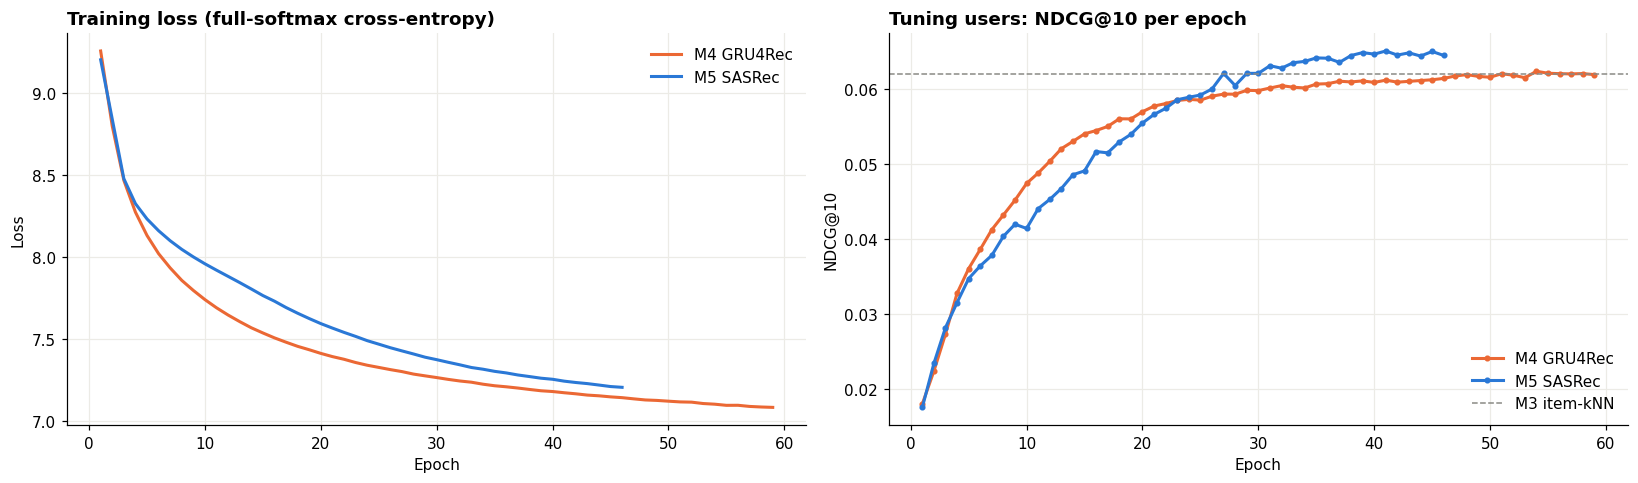

In [25]:
# ==============================
# 7.3.3 M5 — SASRec
# ==============================
torch.manual_seed(SEED)
sas = SASRec(N_ITEMS, d=64, n_layers=2, n_heads=2, dropout=0.5)
log_sas = train_model(sas, lr=1e-3)

for s in ["valid", "test"]:
    evaluate("M5 SASRec", s, neural_scorer(sas, s))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for log, name, c in [(log_gru, "M4 GRU4Rec", ORANGE), (log_sas, "M5 SASRec", BLUE)]:
    axes[0].plot(log["epoch"], log["loss"], color=c, lw=2, label=name)
    axes[1].plot(log["epoch"], log["NDCG@10"], color=c, lw=2, marker="o", ms=3, label=name)
axes[1].axhline(m3_tune["NDCG@10"], color=GREY, ls="--", lw=1, label="M3 item-kNN")
axes[0].set(title="Training loss (full-softmax cross-entropy)", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Tuning users: NDCG@10 per epoch", xlabel="Epoch", ylabel="NDCG@10")
for ax in axes:
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

show_results()

### 7.3 Self-Supervised Sequential Models — Key Findings

| Model | Split | HR@10 | NDCG@10 | HR@20 | NDCG@20 | Coverage@10 | Tail share@10 |
|---|---|---|---|---|---|---|---|
| M3 Sequential item-kNN | valid | 10.41% | 0.0616 | 14.24% | 0.0713 | 92.8% | 17.1% |
| M3 Sequential item-kNN | test | 9.51% | **0.0570** | 12.82% | 0.0653 | 91.5% | 17.2% |
| M4 GRU4Rec | valid | 11.28% | 0.0620 | 16.31% | 0.0747 | 57.0% | 10.4% |
| M4 GRU4Rec | test | 9.59% | 0.0533 | 13.92% | 0.0642 | 56.7% | 11.4% |
| M5 SASRec | valid | **11.71%** | **0.0648** | **16.76%** | **0.0775** | 57.7% | 11.9% |
| M5 SASRec | test | **9.97%** | 0.0561 | **14.36%** | **0.0671** | 58.0% | 13.7% |

**1. Training behaved well.**
- Both models learned steadily with no sign of overfitting: training loss kept falling, and tuning NDCG@10 rose, then plateaued.
- **SASRec** peaked at **epoch 41** (tuning NDCG@10 = 0.0651), and **GRU4Rec** at **epoch 54** (0.0624). Each epoch took 15–18 s on a T4, so each model trained in \~15 minutes.
- GRU4Rec learns faster at first (it is ahead until \~epoch 22), but SASRec keeps improving and ends higher. With more capacity to model the history, SASRec needs more epochs to exploit it.

**2. SASRec beats GRU4Rec on every metric.**
- On test: NDCG@10 **+5%** (0.0561 vs. 0.0533) and HR@10 **+4%** (9.97% vs. 9.59%).
- This is consistent with 5.4: self-attention can weigh *any* earlier item (recent purchases *and* the long-term profile), while the GRU's compressed state favors the last steps.

**3. Neural vs. item-kNN: on validation the neural models win; on test it is a tie at the top.**
- On validation, SASRec leads M3 on every accuracy metric (NDCG@10 0.0648 vs. 0.0616, HR@20 16.8% vs. 14.2%).
- On test, SASRec leads in **HR@10 (+5%), HR@20 (+12%) and NDCG@20 (+3%)**, but M3 keeps a slight edge in **NDCG@10 (0.0570 vs. 0.0561)**. M3 places its hits higher in the top 10; SASRec finds more relevant items deeper in the list.

**4. The neural models drop more from validation to test, and part of that drop is unfair.**
- NDCG@10 falls **13–14%** for SASRec and GRU4Rec, vs. **7.5%** for M3.
- The protocols differ. For test, **M3 rebuilds its statistics from train + valid**, so it benefits from the 94,762 extra (and more recent) interactions. The neural models were trained **on train only** and never saw the validation interactions as training targets.
- A fair comparison requires **retraining the neural models on train + valid** with the number of epochs chosen on validation (Section 7.4).

**5. Neural models are less diverse.**
- They cover **57–58%** of the catalog (vs. 92% for M3), and 11–14% of their recommendations come from the long tail (vs. 17%).
- A full softmax trained on next-item targets learns the global popularity of items through the output embeddings, which pushes popular products up for everyone.
- This is a business trade-off: M3 explores more of the catalog, while SASRec concentrates on likely hits.

### 7.4 Fair Refit: Neural Models Trained on Train + Valid

For the test evaluation, M3 builds its item statistics from **train + valid**, but M4 and M5 were trained on **train** only. To compare on equal terms, both neural models are **retrained from scratch on the train + valid sequences**, for the **number of epochs selected on validation** (no early stopping, since no held-out data remains). They are then evaluated on test.

Results from the train-only models are kept in the table for transparency.

In [26]:
# ==============================
# 7.4 Refit M4 and M5 on train + valid for a fixed number of epochs
# ==============================
full_seqs = EVAL["test"]["hist"]                                # train + valid sequences
X_FULL = torch.from_numpy(pad_right([s[:-1] for s in full_seqs]))
Y_FULL = torch.from_numpy(pad_right([s[1:] for s in full_seqs]))
print(f"Refit sequences: {len(X_FULL):,} | supervised positions: {(Y_FULL > 0).sum().item():,} "
      f"(+{(Y_FULL > 0).sum().item() / (Y_TRAIN > 0).sum().item() - 1:.0%} vs. train only)")

def fit_fixed(model, X, Y, epochs, batch_size=128, lr=1e-3, weight_decay=0.0):
    model.to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        tot, n = 0.0, 0
        for b in range(0, len(perm), batch_size):
            ii = perm[b:b + batch_size]
            xb, yb = X[ii].to(DEV), Y[ii].to(DEV)
            m = yb > 0
            with torch.autocast(DEV.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(xb)[m] @ model.item_emb.weight.T
            logits = logits.float()
            logits[:, 0] = -1e4
            loss = F.cross_entropy(logits, yb[m])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            tot += loss.item() * m.sum().item()
            n += m.sum().item()
        if ep % 10 == 0 or ep == epochs:
            print(f"  epoch {ep:3d}/{epochs} | loss {tot / n:.4f} | {(time.time() - t0) / 60:.1f} min")
    return model

EPOCHS_GRU = int(log_gru.loc[log_gru["NDCG@10"].idxmax(), "epoch"])
EPOCHS_SAS = int(log_sas.loc[log_sas["NDCG@10"].idxmax(), "epoch"])

print(f"\nRefitting GRU4Rec for {EPOCHS_GRU} epochs")
torch.manual_seed(SEED)
gru_full = fit_fixed(GRU4Rec(N_ITEMS, d=64, dropout=0.3), X_FULL, Y_FULL, EPOCHS_GRU)
evaluate("M4 GRU4Rec (refit train+valid)", "test", neural_scorer(gru_full, "test"))

print(f"\nRefitting SASRec for {EPOCHS_SAS} epochs")
torch.manual_seed(SEED)
sas_full = fit_fixed(SASRec(N_ITEMS, d=64, n_layers=2, n_heads=2, dropout=0.5), X_FULL, Y_FULL, EPOCHS_SAS)
evaluate("M5 SASRec (refit train+valid)", "test", neural_scorer(sas_full, "test"))

show_results("test")

Refit sequences: 94,762 | supervised positions: 611,960 (+18% vs. train only)

Refitting GRU4Rec for 54 epochs
  epoch  10/54 | loss 7.7322 | 1.0 min
  epoch  20/54 | loss 7.4354 | 2.0 min
  epoch  30/54 | loss 7.3119 | 2.9 min
  epoch  40/54 | loss 7.2355 | 3.9 min
  epoch  50/54 | loss 7.1858 | 4.9 min
  epoch  54/54 | loss 7.1706 | 5.3 min

Refitting SASRec for 41 epochs
  epoch  10/41 | loss 7.9444 | 1.5 min
  epoch  20/41 | loss 7.5785 | 3.1 min
  epoch  30/41 | loss 7.3967 | 4.6 min
  epoch  40/41 | loss 7.2953 | 6.1 min
  epoch  41/41 | loss 7.2880 | 6.3 min


,,HR@10,NDCG@10,HR@20,NDCG@20,coverage@10,tail_share@10
model,split,,,,,,
M0 Popularity (all-time),test,0.0249,0.0127,0.0380,0.0160,0.1%,0.0%
M1 Recent popularity (W=1m),test,0.0603,0.0318,0.0887,0.0390,5.7%,8.4%
M2 Markov transitions,test,0.0661,0.0394,0.0908,0.0456,96.7%,22.3%
M3 Sequential item-kNN,test,0.0951,0.0570,0.1282,0.0653,91.5%,17.2%
M4 GRU4Rec,test,0.0959,0.0533,0.1392,0.0642,56.7%,11.4%
M5 SASRec,test,0.0997,0.0561,0.1436,0.0671,58.0%,13.7%
M4 GRU4Rec (refit train+valid),test,0.1045,0.0584,0.1506,0.0700,55.5%,11.5%
M5 SASRec (refit train+valid),test,0.1060,0.0592,0.1522,0.0708,55.1%,12.8%


### 7.5 Hybrid: Item-kNN + SASRec (M6)

M3 and M5 have complementary strengths:
- **M3** (unsupervised) relies on exact co-occurrence evidence. It is precise at the very top of the list and explores the catalog widely.
- **M5** (self-supervised) generalizes to items never seen near the user's history, and finds more hits deeper in the list.

**M6** combines them by **score fusion**. Each model's scores are standardized per user (z-score over the catalog), then mixed:

score = α · z(M3) + (1 − α) · z(M5)

The weight α is tuned on the 30k tuning users with the train-only SASRec. The test evaluation uses the refit SASRec and M3 with train + valid statistics.

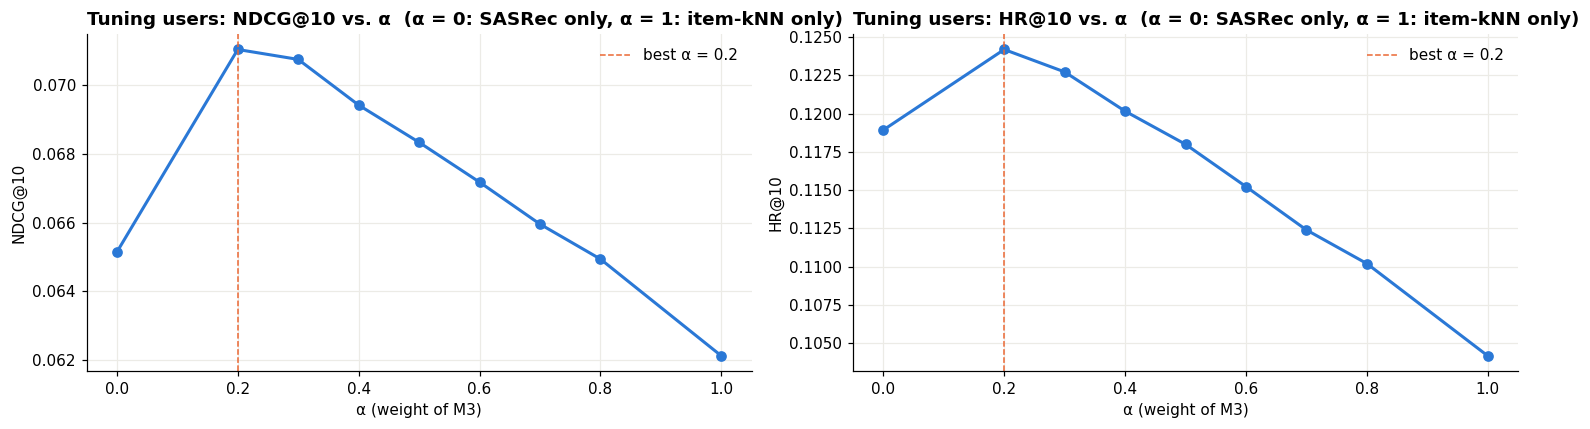

alpha,HR@10,NDCG@10,HR@20,NDCG@20,coverage@10,tail_share@10
0.000000,0.1189,0.0651,0.1684,0.0775,44.4%,11.8%
0.200000,0.1242,0.0710,0.1751,0.0838,58.6%,12.5%
0.300000,0.1227,0.0707,0.1738,0.0836,64.0%,13.4%
0.400000,0.1202,0.0694,0.1713,0.0823,68.0%,14.3%
0.500000,0.1180,0.0683,0.1669,0.0806,70.8%,15.0%
0.600000,0.1152,0.0672,0.1620,0.0789,73.0%,15.7%
0.700000,0.1124,0.0660,0.1576,0.0773,74.8%,16.3%
0.800000,0.1102,0.0649,0.1524,0.0755,76.0%,16.7%
1.000000,0.1042,0.0621,0.1416,0.0716,78.4%,17.0%


,,HR@10,NDCG@10,HR@20,NDCG@20,coverage@10,tail_share@10
model,split,,,,,,
M0 Popularity (all-time),test,0.0249,0.0127,0.0380,0.0160,0.1%,0.0%
M1 Recent popularity (W=1m),test,0.0603,0.0318,0.0887,0.0390,5.7%,8.4%
M2 Markov transitions,test,0.0661,0.0394,0.0908,0.0456,96.7%,22.3%
M3 Sequential item-kNN,test,0.0951,0.0570,0.1282,0.0653,91.5%,17.2%
M4 GRU4Rec,test,0.0959,0.0533,0.1392,0.0642,56.7%,11.4%
M5 SASRec,test,0.0997,0.0561,0.1436,0.0671,58.0%,13.7%
M4 GRU4Rec (refit train+valid),test,0.1045,0.0584,0.1506,0.0700,55.5%,11.5%
M5 SASRec (refit train+valid),test,0.1060,0.0592,0.1522,0.0708,55.1%,12.8%
M6 Hybrid kNN+SASRec (α=0.2),test,0.1132,0.0651,0.1588,0.0765,69.8%,13.0%


In [27]:
# ==============================
# 7.5 M6 — Hybrid score fusion (M3 item-kNN + M5 SASRec)
# ==============================
def zscore_rows(S):
    S = S.astype(np.float32)
    return (S - S.mean(axis=1, keepdims=True)) / (S.std(axis=1, keepdims=True) + 1e-8)

def hybrid_scorer(split, neural_model, alpha):
    f_knn = knn_scorer(split, **cfg)
    f_nn = neural_scorer(neural_model, split)
    def f(idx):
        return alpha * zscore_rows(f_knn(idx)) + (1 - alpha) * zscore_rows(f_nn(idx))
    return f

alphas = [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
hyb = pd.DataFrame([{**evaluate("tune", "tune", hybrid_scorer("tune", sas, a), store=False), "alpha": a} for a in alphas])
best_alpha = float(hyb.loc[hyb["NDCG@10"].idxmax(), "alpha"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, met in zip(axes, ["NDCG@10", "HR@10"]):
    ax.plot(hyb["alpha"], hyb[met], color=BLUE, lw=2, marker="o")
    ax.axvline(best_alpha, color=ORANGE, ls="--", lw=1, label=f"best α = {best_alpha}")
    ax.set(title=f"Tuning users: {met} vs. α  (α = 0: SASRec only, α = 1: item-kNN only)", xlabel="α (weight of M3)", ylabel=met)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()
display(hyb[["alpha", "HR@10", "NDCG@10", "HR@20", "NDCG@20", "coverage@10", "tail_share@10"]]
        .style.format({c: "{:.4f}" for c in ["HR@10", "NDCG@10", "HR@20", "NDCG@20"]} |
                      {"coverage@10": "{:.1%}", "tail_share@10": "{:.1%}"}).hide(axis="index"))

evaluate(f"M6 Hybrid kNN+SASRec (α={best_alpha})", "valid", hybrid_scorer("valid", sas, best_alpha))
evaluate(f"M6 Hybrid kNN+SASRec (α={best_alpha})", "test", hybrid_scorer("test", sas_full, best_alpha))
show_results("test")

### 7.4–7.5 Fair Refit and Hybrid — Key Findings

**1. The refit closes the protocol gap, and the neural models now beat item-kNN on every accuracy metric.**

| Model (test) | HR@10 | NDCG@10 | HR@20 | NDCG@20 | Coverage@10 |
|---|---|---|---|---|---|
| M3 Sequential item-kNN | 9.51% | 0.0570 | 12.82% | 0.0653 | 91.5% |
| M4 GRU4Rec (train only → refit) | 9.59% → **10.45%** | 0.0533 → **0.0584** | 13.92% → **15.06%** | 0.0642 → **0.0700** | 55.5% |
| M5 SASRec (train only → refit) | 9.97% → **10.60%** | 0.0561 → **0.0592** | 14.36% → **15.22%** | 0.0671 → **0.0708** | 55.1% |

- Retraining on train + valid (+18% supervised positions, all of them *recent*) raises NDCG@10 by **+9.6% for GRU4Rec** and **+5.5% for SASRec**.
- SASRec's validation → test drop shrinks from 13% to **8.6%**, in line with M3 (7.5%). The earlier gap was a **protocol artifact**, not weaker generalization.
- With a fair protocol, SASRec beats M3 by **+4% NDCG@10, +11% HR@10 and +19% HR@20**. It still leads GRU4Rec, but by a smaller margin (+1.4% NDCG@10).
- Refitting is cheap: 5–6 minutes per model on a T4.

**2. The hybrid (M6) is the best model, by a clear margin.**
- On the tuning users, NDCG@10 rises from **0.0651 (SASRec alone)** to **0.0710 at α = 0.2** (+9%), then declines steadily toward 0.0621 (item-kNN alone).
- On **test**, M6 reaches **HR@10 = 11.32%, NDCG@10 = 0.0651, HR@20 = 15.88%, NDCG@20 = 0.0765**:
  - **+10% NDCG@10** and **+7% HR@10** over the refit SASRec;
  - **+14% NDCG@10** and **+19% HR@10** over M3;
  - **2.0× NDCG@10** over recent popularity (M1) and **5.1×** over all-time popularity (M0).
- The gains hold on validation and test, so they are not a tuning artifact.

**3. A small weight on M3 goes a long way.**
- M3's standardized scores are **spiky**: a handful of items with direct co-occurrence evidence get very high z-scores, and the rest are near zero. Even with α = 0.2, those few items are pushed into SASRec's top 10.
- The two models are therefore complementary. SASRec provides a smooth, generalizing ranking over the whole catalog, and M3 injects **precise, evidence-based candidates** at the top.

**4. The hybrid also recovers diversity.**
- Coverage rises from **55% (SASRec) to 70%** and the long-tail share stays at \~13%, so the accuracy gain does not come from concentrating on popular items.
- As α grows, coverage keeps increasing (up to 78% on the tuning users), which gives a direct **accuracy-vs-diversity dial** if the business wants more exploration.

### 7.6 Segment Analysis: Where Does Each Model Win?

**Questions (test set):**
- How does performance change with **history length**? Do neural models need longer histories?
- How does it change with the **time gap** before the target? Section 5.4 showed that coherence with the previous item decays over time: is the same-session case the easiest?
- How **complementary** are M3 and SASRec? How many targets does each one find that the other misses?

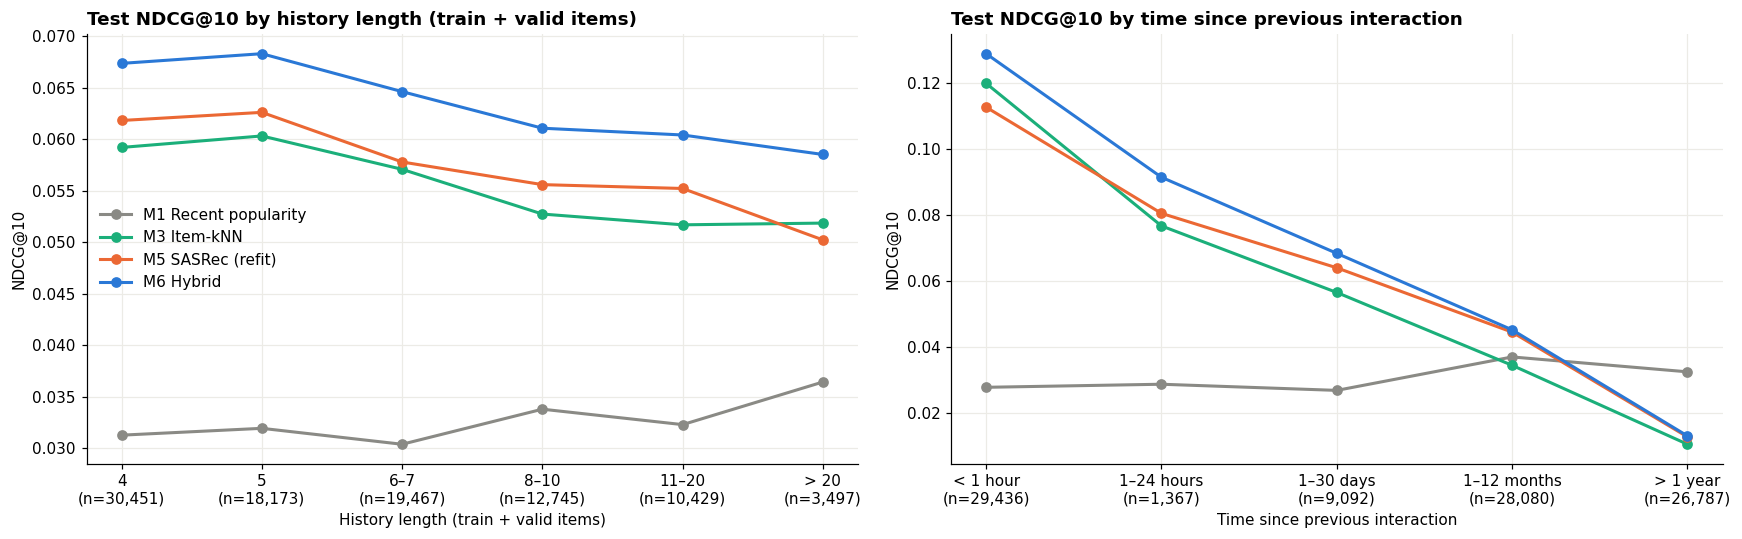

,M1 Recent popularity,M3 Item-kNN,M5 SASRec (refit),M6 Hybrid,users,M6 vs M3
len_bin,,,,,,
4,0.0312,0.0592,0.0618,0.0674,"30,451",+14%
5,0.0319,0.0603,0.0626,0.0683,"18,173",+13%
6–7,0.0304,0.0571,0.0578,0.0646,"19,467",+13%
8–10,0.0338,0.0527,0.0556,0.0611,"12,745",+16%
11–20,0.0323,0.0517,0.0552,0.0604,"10,429",+17%
> 20,0.0364,0.0519,0.0502,0.0585,"3,497",+13%


,M1 Recent popularity,M3 Item-kNN,M5 SASRec (refit),M6 Hybrid,users,M6 vs M3
gap_bin,,,,,,
< 1 hour,0.0279,0.1199,0.1127,0.1289,"29,436",+7%
1–24 hours,0.0288,0.0768,0.0806,0.0915,"1,367",+19%
1–30 days,0.0269,0.0566,0.0641,0.0684,"9,092",+21%
1–12 months,0.0371,0.0345,0.0446,0.0453,"28,080",+31%
> 1 year,0.0325,0.0106,0.0128,0.0131,"26,787",+24%


Both hit:          6.41%
Only M3 hits:      3.10%
Only SASRec hits:  4.19%
Either (oracle):   13.70%   ← ceiling for a perfect switch between the two
M6 Hybrid:         11.32%


In [28]:
# ==============================
# 7.6 Segment analysis on test
# ==============================
E = EVAL["test"]
MODELS = {
    "M1 Recent popularity": (f"M1 Recent popularity (W={best_W}m)", GREY),
    "M3 Item-kNN": ("M3 Sequential item-kNN", GREEN),
    "M5 SASRec (refit)": ("M5 SASRec (refit train+valid)", ORANGE),
    "M6 Hybrid": (f"M6 Hybrid kNN+SASRec (α={best_alpha})", BLUE),
}

def ndcg10(r):
    return np.where(r < 10, 1 / np.log2(r + 2), 0)

seg = pd.DataFrame({
    "len_bin": pd.cut(E["hist_len"], [0, 4, 5, 7, 10, 20, np.inf], labels=["4", "5", "6–7", "8–10", "11–20", "> 20"]),
    "gap_bin": pd.cut(E["gap"], [-0.01, 1 / 24, 1, 30, 365, np.inf],
                      labels=["< 1 hour", "1–24 hours", "1–30 days", "1–12 months", "> 1 year"]),
})
for label, (name, _) in MODELS.items():
    seg[label] = ndcg10(RANKS[(name, "test")])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col, title in [(axes[0], "len_bin", "History length (train + valid items)"),
                       (axes[1], "gap_bin", "Time since previous interaction")]:
    g = seg.groupby(col, observed=True)
    sizes = g.size()
    for label, (_, c) in MODELS.items():
        ax.plot(range(len(sizes)), g[label].mean(), color=c, lw=2, marker="o", label=label)
    ax.set_xticks(range(len(sizes)))
    ax.set_xticklabels([f"{k}\n(n={v:,})" for k, v in sizes.items()])
    ax.set(title=f"Test NDCG@10 by {title.lower()}", xlabel=title, ylabel="NDCG@10")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

for col in ["len_bin", "gap_bin"]:
    t = seg.groupby(col, observed=True)[list(MODELS)].mean()
    t["users"] = seg.groupby(col, observed=True).size()
    t["M6 vs M3"] = t["M6 Hybrid"] / t["M3 Item-kNN"] - 1
    display(t.style.format({**{m: "{:.4f}" for m in MODELS}, "users": "{:,}", "M6 vs M3": "{:+.0%}"}))

# ==============================
# 7.6.2 Complementarity of M3 and SASRec (HR@10 on test)
# ==============================
hit3 = RANKS[(MODELS["M3 Item-kNN"][0], "test")] < 10
hit5 = RANKS[(MODELS["M5 SASRec (refit)"][0], "test")] < 10
hit6 = RANKS[(MODELS["M6 Hybrid"][0], "test")] < 10
print(f"Both hit:          {(hit3 & hit5).mean():.2%}")
print(f"Only M3 hits:      {(hit3 & ~hit5).mean():.2%}")
print(f"Only SASRec hits:  {(~hit3 & hit5).mean():.2%}")
print(f"Either (oracle):   {(hit3 | hit5).mean():.2%}   ← ceiling for a perfect switch between the two")
print(f"M6 Hybrid:         {hit6.mean():.2%}")

### 7.7 Example Recommendations (M6 Hybrid, Test Set)

A qualitative check: for a few test users, we show the last items of their history, the actual next product, and the hybrid's top 10.

In [29]:
# ==============================
# 7.7 Qualitative examples
# ==============================
f_m6 = hybrid_scorer("test", sas_full, best_alpha)
r6 = RANKS[(MODELS["M6 Hybrid"][0], "test")]
rng_ex = np.random.default_rng(SEED)
mid_len = (E["hist_len"] >= 5) & (E["hist_len"] <= 8)
picks = list(rng_ex.choice(np.where((r6 < 3) & mid_len)[0], 2, replace=False)) + \
        list(rng_ex.choice(np.where((r6 >= 100) & mid_len)[0], 1, replace=False))

def label(i):
    return f"{str(info.at[i, 'title'])[:70]}  [{info.at[i, 'platform'] or '?'}]"

for p in picks:
    S = f_m6(np.array([p]))[0]
    S[0] = -np.inf
    S[E["hist"][p]] = -np.inf
    top = np.argsort(-S)[:10]
    target = E["target"][p]
    print("=" * 110)
    print(f"User #{p} | history length {E['hist_len'][p]} | target rank (M6) = {r6[p]:.0f} | gap = {E['gap'][p]:.1f} days")
    print("Last items in history (oldest → newest):")
    for i in E["hist"][p][-5:]:
        print(f"   · {label(i)}")
    print(f"Actual next product:\n   ★ {label(target)}")
    print("M6 top 10:")
    for k, i in enumerate(top, 1):
        print(f"  {k:2d}. {'✓' if i == target else ' '} {label(i)}")

User #8515 | history length 5 | target rank (M6) = 0 | gap = 0.0 days
Last items in history (oldest → newest):
   · LEGO: Marvel - PC  [PC]
   · The First Templar - Xbox 360  [Xbox 360]
   · Aliens vs. Predator - PC  [PC]
   · Super Mario Galaxy (Nintendo Selects)  [Wii]
   · X-Men Origins: Wolverine - Uncaged Edition - PC  [PC]
Actual next product:
   ★ Batman: Arkham Asylum - Xbox 360  [Xbox 360]
M6 top 10:
   1. ✓ Batman: Arkham Asylum - Xbox 360  [Xbox 360]
   2.   Star Wars The Force Unleashed: Ultimate Sith Edition - Playstation 3  [PlayStation 3]
   3.   PROTOTYPE - Playstation 3  [PlayStation Systems]
   4.   Star Wars: The Force Unleashed II - PC  [PC]
   5.   inFAMOUS - Playstation 3  [PlayStation 3]
   6.   Ghostbusters: The Video Game - Playstation 3  [PlayStation 3]
   7.   Marvel Ultimate Alliance 2 - Nintendo Wii  [Wii]
   8.   Batman: Arkham Origins Collectible Case for PS3  [PlayStation 3]
   9.   Spider-Man: Web of Shadows - PlayStation 2  [PlayStation 2]
  10.   Dant

### 7.6–7.7 Segment Analysis and Examples — Key Findings

**1. History length: shorter histories are slightly easier, and the hybrid wins everywhere.**

| History length | Users | M1 | M3 | M5 SASRec | **M6 Hybrid** | M6 vs. M3 |
|---|---|---|---|---|---|---|
| 4 | 30,451 | 0.0312 | 0.0592 | 0.0618 | **0.0674** | +14% |
| 5 | 18,173 | 0.0319 | 0.0603 | 0.0626 | **0.0683** | +13% |
| 6–7 | 19,467 | 0.0304 | 0.0571 | 0.0578 | **0.0646** | +13% |
| 8–10 | 12,745 | 0.0338 | 0.0527 | 0.0556 | **0.0611** | +16% |
| 11–20 | 10,429 | 0.0323 | 0.0517 | 0.0552 | **0.0604** | +17% |
| > 20 | 3,497 | 0.0364 | 0.0519 | 0.0502 | **0.0585** | +13% |

- Personalized models do **not** need long histories: NDCG@10 is highest for users with 4–5 items and declines slowly after that. Heavy users have broader, less predictable tastes, while popularity (M1) works slightly better for them.
- SASRec beats M3 in every bin except > 20 items, and the hybrid beats both everywhere (+13–17% over M3).

**2. Time gap: the dominant factor, with a 10× difference between segments.**

| Gap before target | Users | M1 | M3 | M5 SASRec | **M6 Hybrid** |
|---|---|---|---|---|---|
| < 1 hour | 29,436 | 0.0279 | 0.1199 | 0.1127 | **0.1289** |
| 1–24 hours | 1,367 | 0.0288 | 0.0768 | 0.0806 | **0.0915** |
| 1–30 days | 9,092 | 0.0269 | 0.0566 | 0.0641 | **0.0684** |
| 1–12 months | 28,080 | 0.0371 | 0.0345 | 0.0446 | **0.0453** |
| > 1 year | 26,787 | **0.0325** | 0.0106 | 0.0128 | 0.0131 |

- **Same-session targets (< 1 hour, 31% of users) are by far the easiest** (NDCG@10 = 0.129). In that segment **M3 beats SASRec** (0.120 vs. 0.113): direct co-occurrence evidence is exactly what a shopping session needs.
- As the gap grows, **SASRec overtakes M3** and the hybrid's advantage over M3 grows from +7% to +31%, confirming that the long-term profile matters more than the last item for later purchases (5.4).
- **For customers returning after more than a year (28% of users), every personalized model falls below recent popularity** (0.013 vs. 0.033). Their history belongs to an earlier console generation (5.3), so item-to-item knowledge is obsolete and they behave like cold-start users. This motivates the **gap-aware switch** in 7.8.

**3. M3 and SASRec are complementary, and the hybrid captures most of it.**
- Test HR@10: both hit **6.41%**, only M3 **3.10%**, only SASRec **4.19%**. A perfect switch between the two (oracle) would reach **13.70%**.
- The hybrid reaches **11.32%**, i.e. **83% of the oracle ceiling**, without knowing in advance which model is right for each user.

**4. Examples: coherent lists, and an informative failure.**
- **User #8515** (PC, Wii and Xbox 360 games from \~2009, including *X-Men Origins: Wolverine*): the target *Batman: Arkham Asylum* is **ranked #1**. The rest of the list is the same **era and genre** (*Prototype*, *inFAMOUS*, *Ghostbusters*, *Marvel Ultimate Alliance 2*): the model learned launch-period cohorts without any metadata.
- **User #72682** (Switch carrying cases + *Hollow Knight*): the *Switch Pro Controller* is **ranked #3**, and the whole top 10 is the **Switch ecosystem** (screen protector, microSD card, DLC passes, first-party games).
- **User #41497, a miss** (rank 301, 232 days later): an Xbox 360 action-game buyer who owns *Ninja Gaiden II* buys *Ninja Gaiden Sigma 2* for **PS3**. The recommendations have the right genre and era (*Gears of War 2*, *Mass Effect*, *Halo 3*, *BioShock*), but an ID-based model cannot know that the target is **the same game on another console**. Title or content features would close this gap (see Next Steps).
- Both hits happened within the same session (gap = 0 days), consistent with finding 2.

### 7.8 Gap-Aware Switch (M7)

Section 7.6 showed that personalized models fail for customers returning after a long absence, while recent popularity does not degrade. The **time since the customer's last interaction is known at recommendation time**, so it can be used legitimately to choose the model:

- gap ≤ T → **M6 Hybrid** (personalized)
- gap > T → **M1 Recent popularity** (what is selling now)

The threshold **T** is chosen on validation. Both models' per-user ranks are already stored, so the switch is evaluated without re-scoring. Coverage and tail share are not computed for this combination.

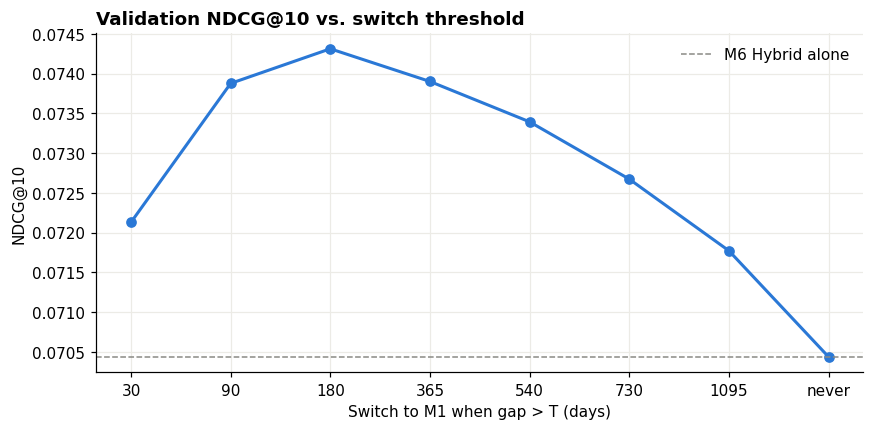

T_days,share_switched,HR@10,NDCG@10,HR@20,NDCG@20
30.000000,49.2%,0.1248,0.0721,0.1730,0.0843
90.000000,39.2%,0.1284,0.0739,0.1789,0.0866
180.000000,30.6%,0.1298,0.0743,0.1823,0.0876
365.000000,19.7%,0.1297,0.0739,0.1836,0.0875
540.000000,13.7%,0.1288,0.0734,0.1826,0.0870
730.000000,9.7%,0.1275,0.0727,0.1809,0.0862
1095.000000,5.2%,0.1257,0.0718,0.1788,0.0851
inf,0.0%,0.1233,0.0704,0.1752,0.0835


Best threshold: T = 180 days


,,HR@10,NDCG@10,HR@20,NDCG@20,coverage@10,tail_share@10
model,split,,,,,,
M0 Popularity (all-time),test,0.0249,0.0127,0.0380,0.0160,0.1%,0.0%
M1 Recent popularity (W=1m),test,0.0603,0.0318,0.0887,0.0390,5.7%,8.4%
M2 Markov transitions,test,0.0661,0.0394,0.0908,0.0456,96.7%,22.3%
M3 Sequential item-kNN,test,0.0951,0.0570,0.1282,0.0653,91.5%,17.2%
M4 GRU4Rec,test,0.0959,0.0533,0.1392,0.0642,56.7%,11.4%
M5 SASRec,test,0.0997,0.0561,0.1436,0.0671,58.0%,13.7%
M4 GRU4Rec (refit train+valid),test,0.1045,0.0584,0.1506,0.0700,55.5%,11.5%
M5 SASRec (refit train+valid),test,0.1060,0.0592,0.1522,0.0708,55.1%,12.8%
M6 Hybrid kNN+SASRec (α=0.2),test,0.1132,0.0651,0.1588,0.0765,69.8%,13.0%


In [30]:
# ==============================
# 7.8 M7 — Gap-aware switch between M6 Hybrid and M1 Recent popularity
# ==============================
M6_NAME, M1_NAME = MODELS["M6 Hybrid"][0], MODELS["M1 Recent popularity"][0]

def switch_ranks(split, T):
    return np.where(EVAL[split]["gap"] > T, RANKS[(M1_NAME, split)], RANKS[(M6_NAME, split)])

def metrics_from_ranks(r):
    out = {}
    for k in (10, 20):
        out[f"HR@{k}"] = (r < k).mean()
        out[f"NDCG@{k}"] = np.where(r < k, 1 / np.log2(r + 2), 0).mean()
    return out

thresholds = [30, 90, 180, 365, 540, 730, 1095, np.inf]
sw = pd.DataFrame([{"T_days": T, "share_switched": (EVAL["valid"]["gap"] > T).mean(),
                    **metrics_from_ranks(switch_ranks("valid", T))} for T in thresholds])
best_T = sw.loc[sw["NDCG@10"].idxmax(), "T_days"]

fig, ax = plt.subplots(figsize=(9, 4))
xl = [f"{t:.0f}" if np.isfinite(t) else "never" for t in thresholds]
ax.plot(xl, sw["NDCG@10"], color=BLUE, lw=2, marker="o")
ax.axhline(sw["NDCG@10"].iloc[-1], color=GREY, ls="--", lw=1, label="M6 Hybrid alone")
ax.set(title="Validation NDCG@10 vs. switch threshold", xlabel="Switch to M1 when gap > T (days)", ylabel="NDCG@10")
ax.legend(frameon=False)
plt.show()
display(sw.style.format({"share_switched": "{:.1%}", **{c: "{:.4f}" for c in ["HR@10", "NDCG@10", "HR@20", "NDCG@20"]}}).hide(axis="index"))
print(f"Best threshold: T = {best_T:.0f} days")

M7_NAME = f"M7 Gap-aware switch (M1 if gap > {best_T:.0f}d, else M6)"
for s in ["valid", "test"]:
    r = switch_ranks(s, best_T)
    RESULTS[:] = [x for x in RESULTS if not (x["model"] == M7_NAME and x["split"] == s)]
    RESULTS.append({"model": M7_NAME, "split": s, **metrics_from_ranks(r), "coverage@10": np.nan, "tail_share@10": np.nan})
    RANKS[(M7_NAME, s)] = r

def show_results(split=None):
    df = pd.DataFrame(RESULTS)
    if split:
        df = df[df["split"] == split]
    metric_cols = [c for c in df.columns if c.startswith(("HR", "NDCG"))]
    display(df.set_index(["model", "split"]).style
            .format("{:.4f}", subset=metric_cols)
            .format("{:.1%}", subset=["coverage@10", "tail_share@10"], na_rep="—"))

show_results("test")

### 7.8 Gap-Aware Switch — Key Findings

**1. A one-line business rule beats every model.**
- On validation, NDCG@10 rises from **0.0704** (M6 alone) to **0.0743** with the switch at **T = 180 days** (+5.5%), which routes 30.6% of users to recent popularity.
- The curve is smooth with a clear peak. Switching too early (T = 30 days, 49% of users) throws away useful personalization; switching too late (T ≥ 2 years) leaves many stale histories in the hybrid.

**2. On test the gain is even larger.**

| Model (test) | HR@10 | NDCG@10 | HR@20 | NDCG@20 |
|---|---|---|---|---|
| M6 Hybrid | 11.32% | 0.0651 | 15.88% | 0.0765 |
| **M7 Gap-aware switch (T = 180 days)** | **12.32%** | **0.0711** | **16.98%** | **0.0828** |

- **+9.2% NDCG@10** and **+8.8% HR@10** over M6, with no extra training and no extra inference cost.
- The gain is larger on test than on validation because test targets come after longer gaps (28% of test users return after more than a year).

**3. Why 180 days and not 1 year?**
- Section 7.6 showed that personalized models still beat popularity in the 1–12 month segment *on average*. Within that segment, though, value decays quickly: after \~6 months, a customer's last purchases say less about the next one than what is currently trending.
- In business terms, **after six months of inactivity a customer should be treated as a returning (near cold-start) customer**, and shown what is selling now.

## 8. Conclusions

### 8.1 Final Results (Test Set, Full-Catalog Ranking over 25,612 Products)

| Model | Paradigm | HR@10 | NDCG@10 | HR@20 | NDCG@20 | Coverage@10 |
|---|---|---|---|---|---|---|
| M0 Popularity (all-time) | Baseline | 2.49% | 0.0127 | 3.80% | 0.0160 | 0.1% |
| M1 Recent popularity (1 month) | Baseline | 6.03% | 0.0318 | 8.87% | 0.0390 | 5.7% |
| M2 Markov transitions | Unsupervised | 6.61% | 0.0394 | 9.08% | 0.0456 | 96.7% |
| M3 Sequential item-kNN | Unsupervised | 9.51% | 0.0570 | 12.82% | 0.0653 | 91.5% |
| M4 GRU4Rec (refit) | Self-supervised | 10.45% | 0.0584 | 15.06% | 0.0700 | 55.5% |
| M5 SASRec (refit) | Self-supervised | 10.60% | 0.0592 | 15.22% | 0.0708 | 55.1% |
| M6 Hybrid (item-kNN + SASRec) | Hybrid | 11.32% | 0.0651 | 15.88% | 0.0765 | 69.8% |
| **M7 Gap-aware switch (M6 / M1)** | **Hybrid + rule** | **12.32%** | **0.0711** | **16.98%** | **0.0828** | — |

**The final system (M7) multiplies NDCG@10 by 5.6× over all-time popularity, 2.2× over recent popularity and 1.25× over the best unsupervised model.** One in eight customers finds their actual next product in a top-10 list chosen from more than 25,000 items.

### 8.2 Answers to the Business Questions

- **Can we predict a customer's next product?** Yes, within the limits of a very sparse catalog. In a same-session context (31% of test cases), the hybrid reaches NDCG@10 = 0.129, about **4.6× recent popularity**.
- **Does the order of purchases matter?** Yes. Consecutive products share the specific platform 3.8× and the publisher 4.5× more often than chance. Sequential models beat order-agnostic popularity by a wide margin, and the most recent items carry the most weight (best decay = 0.5).
- **Do deep self-supervised models pay off?** Moderately on their own (SASRec +4% NDCG@10 over item-kNN), and **clearly when combined** with item-kNN (+14% for the hybrid). The two paradigms find different targets: their union would hit 13.7% vs. 10.6% for SASRec alone.
- **Which approach should go to production?** The **gap-aware hybrid (M7)** described in 8.4.

### 8.3 Key Learnings

1. **Recency is everything in video games.** Popularity from the *last month* beats all-time popularity by 2.4×, even though all-time popularity sees the future. Console generations drive demand (PlayStation's share fell from \~33% to \~20% while Nintendo's rose to \~35% after the Switch launch).
2. **The time gap is the strongest driver of predictability.** NDCG@10 varies 10× between same-session targets (0.129) and customers returning after a year (0.013). **No personalized model helps after a long absence**; trending products do.
3. **Unsupervised models are strong, cheap baselines.** Sequential item-kNN, built only from co-occurrence counts with a symmetric window, popularity-aware scoring (β = 0) and recency decay, beat recent popularity by 79% in NDCG@10. It needs no training and no GPU, and recommends from 92% of the catalog.
4. **Evaluation protocol details change conclusions.** Training SASRec on train only made it look worse than item-kNN on test. A fair refit on train + valid reversed the ranking. Ties, history masking and full-catalog ranking were handled explicitly to avoid inflated numbers.
5. **Complementary models beat bigger models.** A 20% weight on item-kNN's sparse, high-confidence evidence added +10% NDCG@10 to SASRec *and* raised catalog coverage from 55% to 70%.
6. **Sparsity defines the problem.** 92.8% of item-to-item transitions are observed only once, 40% of products have fewer than 10 interactions, and only 30.7% of targets ever co-occurred with the user's last item. Generalization through learned embeddings is necessary, but not sufficient.

### 8.4 Business Recommendations

| Context | Recommended logic | Why |
|---|---|---|
| **Active session** (< 1 hour since last action) | Hybrid, with item-kNN carrying high weight ("customers who bought this also bought") | Item-kNN is the best single model in-session (0.120 vs. 0.113 for SASRec) |
| **Recent customer** (≤ 180 days) | M6 Hybrid (SASRec + item-kNN) | Combines the long-term profile with direct co-purchase evidence |
| **Returning customer** (> 180 days) | **Trending now** (M1, last month), optionally filtered to the customer's platform family | Their history belongs to an older console generation |
| **Catalog exploration goals** | Raise α (weight of item-kNN) | Coverage rises from 59% to 78% at a moderate accuracy cost; a business dial for discovery |

The hybrid's z-score fusion and the switch add almost no serving cost: item-kNN is a sparse lookup, and SASRec needs one forward pass per request.

### 8.5 Limitations

- **Benchmark leakage:** leave-one-out is not a global temporal split. For the median user, 19.4% of training data happens after their test target, so absolute metrics are optimistic. Model comparisons stay fair (all models see the same data), and the official split keeps results comparable with the literature.
- **Reviews as a purchase proxy:** interactions are reviews, not purchases. Their order within a session is arbitrary, and customers who do not review are invisible.
- **Single seed, light tuning:** neural models were trained once with standard hyperparameters, and item-kNN was tuned greedily, with some optima at the grid edges. Small differences (e.g., SASRec vs. GRU4Rec, +1.4%) are within plausible run-to-run noise.
- **ID-only models:** no titles, descriptions or prices were used. The models cannot tell that two products are the same game on different consoles (see the *Ninja Gaiden* example in 7.7), and new releases have little history.
- **Offline evaluation only:** HR and NDCG measure whether the *reviewed* next product was ranked high, not whether a recommendation would have *caused* a purchase. An online A/B test is needed to measure business impact.

### 8.6 Next Steps

1. **Content-aware models:** add title or text embeddings (e.g., a sentence encoder over titles and categories) to link platform versions of the same game and to support cold-start releases.
2. **Time-aware sequential models:** feed time gaps into the model (e.g., time-interval-aware self-attention) instead of a hard 180-day switch, or learn a gating network that weights M1, item-kNN and SASRec by context.
3. **Robustness:** multiple seeds with confidence intervals, a wider joint hyperparameter search, and a global temporal split to measure performance without leakage.
4. **Business metrics:** re-rank with margin, stock and diversity constraints, then validate with an A/B test (click-through, conversion, revenue per session).

# End of execution

In [31]:
end = time.time()
delta = end - start
hours, rem = divmod(delta, 3600)
minutes, seconds = divmod(rem, 60)
print(f"Total execution time: {int(hours)}h {int(minutes)}m {seconds:.0f}s")

Total execution time: 1h 14m 23s
